# ResearchNexus – Fine-Tuning a MiniLM Cross-Encoder Reranker on SciFact (PyTorch)

**Project:** ResearchNexus – Scientific Research & Evidence Intelligence
**Model:** `cross-encoder/ms-marco-MiniLM-L-6-v2` (pretrained, then task fine-tuned)
**Primary dataset:** SciFact (BEIR version) **Cross-dataset test:** SCIDOCS (BEIR version)
**Framework:** PyTorch + Hugging Face Transformers **Target runtime:** Kaggle Notebook with GPU (internet must be ON)

> Every number in this notebook is **computed when you run it**. No dataset statistic or metric is hard-coded, and the discussion in Section 18 is generated from the measured values.

## Table of Contents
1. [Project Introduction](#1.-Project-Introduction)
2. [Environment Setup](#2.-Environment-Setup)
3. [Download the Pretrained MiniLM Model](#3.-Download-the-Pretrained-MiniLM-Model)
4. [Download SciFact](#4.-Download-SciFact)
5. [Explore and Understand the Dataset](#5.-Explore-and-Understand-the-Dataset)
6. [Prepare Positive Training Pairs](#6.-Prepare-Positive-Training-Pairs)
7. [Generate Hard Negative Examples](#7.-Generate-Hard-Negative-Examples)
8. [Create the Training and Validation Splits](#8.-Create-the-Training-and-Validation-Splits)
9. [Build a PyTorch Dataset](#9.-Build-a-PyTorch-Dataset)
10. [Evaluate the Pretrained Baseline](#10.-Evaluate-the-Pretrained-Baseline)
11. [Configure PyTorch Fine-Tuning](#11.-Configure-PyTorch-Fine-Tuning)
12. [Implement the Training Loop](#12.-Implement-the-Training-Loop)
13. [Visualize Training Results](#13.-Visualize-Training-Results)
14. [Save the Fine-Tuned Model](#14.-Save-the-Fine-Tuned-Model)
15. [Evaluate the Fine-Tuned Model](#15.-Evaluate-the-Fine-Tuned-Model)
16. [Final Evaluation on Official SciFact Test Data](#16.-Final-Evaluation-on-Official-SciFact-Test-Data)
17. [Independent Evaluation on SCIDOCS](#17.-Independent-Evaluation-on-SCIDOCS)

    **17B.** [Statistical Evidence, Ablation and Robustness](#17B.-Statistical-Evidence,-Ablation-and-Robustness)
18. [Final Results and Research Discussion](#18.-Final-Results-and-Research-Discussion)
19. [Export Artifacts](#19.-Export-Artifacts)

# 1. Project Introduction

## What is ResearchNexus?
**ResearchNexus** is a portfolio project for *scientific research and evidence intelligence*: given a research question or claim, find the passages in the scientific literature that are most relevant to it. This notebook builds and evaluates one core component – a **passage reranker**.

## What is a cross-encoder?
A **bi-encoder** (dense retriever) embeds the query and each document *independently* and compares the vectors. It is fast, but the query and document never "see" each other.

A **cross-encoder** feeds the query and the passage **together** into one Transformer:

```
[CLS] query tokens [SEP] passage tokens [SEP]
```

Self-attention can then compare every query token with every passage token, and a classification head outputs **one relevance logit**. This is usually more accurate, but too slow to run over a whole corpus – so it is used as a **second-stage reranker** on a small candidate list.

## Why is reranking useful in RAG?
In Retrieval-Augmented Generation (RAG) the language model only sees the few passages you pass in. A cheap first-stage retriever (BM25 or dense) fetches, say, 100 candidates; the cross-encoder re-orders them so the best 3–5 passages reach the generator. Better ordering → better grounding → fewer hallucinations.

## Why MiniLM?
`cross-encoder/ms-marco-MiniLM-L-6-v2` is a 6-layer MiniLM (a distilled BERT-family Transformer, roughly 22.7M parameters) already trained for passage ranking on MS MARCO. It is small enough to fine-tune on a free Kaggle GPU in minutes and fast enough for reranking at inference time.

## Why SciFact?
SciFact contains scientific **claims** and a corpus of research abstracts, with human judgments of which abstracts are relevant to each claim. It is a compact, high-quality benchmark for *scientific passage retrieval*, and is available in the standard BEIR format.

## What do we want to achieve?
We **fine-tune** (not train from scratch) the pretrained cross-encoder on SciFact training queries using positives from the relevance judgments and BM25 **hard negatives**, then **measure** – never assume – whether ranking improves compared with the original model, on a held-out validation set, the official test set, and an independent dataset (SCIDOCS).

## Pipeline architecture

```mermaid
flowchart LR
    A[Research query] --> B[BM25 first-stage retrieval]
    B --> C[Top-K candidate passages]
    C --> D["Cross-encoder (MiniLM): query + passage"]
    D --> E[Relevance logit per pair]
    E --> F[Passages re-sorted by score]
    F --> G[RAG generator / evidence view]
```

Plain-text version (renders everywhere, including Kaggle):

```
query ──► BM25 top-K ──► [query ; passage] ──► MiniLM cross-encoder ──► score ──► re-ranked list ──► RAG
```

## Training and evaluation data flow

```mermaid
flowchart TD
    S[SciFact train qrels] --> P[Positive pairs]
    S --> M[BM25 hard-negative mining]
    P --> Q[Query-level split]
    M --> Q
    Q --> TR[Train pairs]
    Q --> VA[Validation pairs]
    TR --> FT[Fine-tune MiniLM]
    VA --> FT
    FT --> EV1[Validation ranking metrics]
    FT --> EV2[Official SciFact test - untouched until the end]
    FT --> EV3[SCIDOCS - cross-dataset generalization]
```

# 2. Environment Setup

We install **only the libraries that are not already available** so we do not disturb the preinstalled Kaggle PyTorch/CUDA stack. Required libraries: `torch`, `transformers`, `sentence-transformers`, `huggingface_hub`, `beir`, `rank-bm25`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `tqdm`, `accelerate`, `datasets`.

> **Kaggle checklist:** turn **Internet ON** (Settings → Internet) and select a **GPU accelerator**. The GPU type can differ between sessions (T4, P100, ...), so nothing below assumes a specific GPU.

In [25]:
import importlib.util
import subprocess
import sys

# pip package name -> importable module name
REQUIRED_PACKAGES = {
    "torch": "torch",
    "transformers": "transformers",
    "sentence-transformers": "sentence_transformers",
    "huggingface_hub": "huggingface_hub",
    "beir": "beir",
    "rank-bm25": "rank_bm25",
    "scikit-learn": "sklearn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "tqdm": "tqdm",
    "accelerate": "accelerate",
    "datasets": "datasets",
}

missing = [pip_name for pip_name, module in REQUIRED_PACKAGES.items() if importlib.util.find_spec(module) is None]

if missing:
    print("Installing missing packages:", missing)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    except subprocess.CalledProcessError as err:
        raise RuntimeError(
            "pip install failed. On Kaggle make sure Internet is enabled in the notebook settings."
        ) from err
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [26]:
import json
import math
import os
import platform
import random
import re
import time
import warnings
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import transformers
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

os.environ["TOKENIZERS_PARALLELISM"] = "false"   # avoids fork warnings with DataLoader workers
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

# ---------- Device detection (no GPU assumption) ----------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"      # fp16 autocast only makes sense on CUDA

print(f"Python version       : {platform.python_version()}")
print(f"PyTorch version      : {torch.__version__}")
print(f"Transformers version : {transformers.__version__}")
print(f"CUDA available       : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    for gpu_index in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(gpu_index)
        print(f"GPU {gpu_index}: {props.name} | memory: {props.total_memory / 1024 ** 3:.1f} GB | "
              f"compute capability: {props.major}.{props.minor}")
    print("Mixed precision (fp16 autocast) will be used.")
else:
    print("\n" + "=" * 80)
    print("WARNING: No GPU detected. Training and evaluation will run on CPU and will be VERY slow.")
    print("On Kaggle: Settings -> Accelerator -> choose a GPU, then restart the session.")
    print("=" * 80)

Python version       : 3.13.16
PyTorch version      : 2.11.0+cu130
Transformers version : 5.20.2
CUDA available       : True
GPU 0: Tesla T4 | memory: 14.6 GB | compute capability: 7.5
GPU 1: Tesla T4 | memory: 14.6 GB | compute capability: 7.5
Mixed precision (fp16 autocast) will be used.


In [27]:
# ---------- Reproducibility ----------
SEED = 42


def set_seed(seed: int) -> None:
    """Fix all random number generators we use."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

# ---------- Output folders ----------
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
ROOT = WORK_DIR / "researchnexus-finetuning"
PRETRAINED_DIR = ROOT / "minilm-pretrained"
FINETUNED_DIR = ROOT / "minilm-scifact-finetuned"
DATA_DIR = ROOT / "datasets"
RESULTS_DIR = ROOT / "results"
PLOTS_DIR = ROOT / "plots"
RAW_DATA_DIR = WORK_DIR / "beir_raw_data"      # raw BEIR downloads (not part of the exported artifacts)

for folder in [ROOT, PRETRAINED_DIR, FINETUNED_DIR, DATA_DIR, RESULTS_DIR, PLOTS_DIR, RAW_DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Running on Kaggle:", ON_KAGGLE)
print("Artifact root    :", ROOT)

# ---------- Central configuration ----------
MODEL_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

CONFIG = {
    # --- fine-tuning hyperparameters (from the project specification) ---
    "epochs": 3,
    "learning_rate": 2e-5,
    "batch_size": 16,
    "gradient_accumulation_steps": 1,
    "max_length": 512,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,            # fraction of total optimizer steps used for LR warm-up
    "max_grad_norm": 1.0,           # gradient clipping threshold
    "early_stopping_patience": 2,   # epochs without validation-loss improvement before stopping
    "early_stopping_min_delta": 1e-4,
    "fp16": USE_AMP,
    "seed": SEED,
    # --- data construction ---
    "hard_negatives_per_positive": 3,
    "bm25_mining_depth": 50,        # hard negatives are chosen from the BM25 top-N
    "validation_fraction": 0.15,    # fraction of training QUERIES held out for validation
    # --- evaluation (identical for pretrained and fine-tuned models) ---
    "rerank_depth": 100,            # BM25 candidates per query that get reranked
    "eval_batch_size": 64,
}
print(json.dumps(CONFIG, indent=2))

Running on Kaggle: True
Artifact root    : /kaggle/working/researchnexus-finetuning
{
  "epochs": 3,
  "learning_rate": 2e-05,
  "batch_size": 16,
  "gradient_accumulation_steps": 1,
  "max_length": 512,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "max_grad_norm": 1.0,
  "early_stopping_patience": 2,
  "early_stopping_min_delta": 0.0001,
  "fp16": true,
  "seed": 42,
  "hard_negatives_per_positive": 3,
  "bm25_mining_depth": 50,
  "validation_fraction": 0.15,
  "rerank_depth": 100,
  "eval_batch_size": 64
}


# 3. Download the Pretrained MiniLM Model

We download `cross-encoder/ms-marco-MiniLM-L-6-v2` with `huggingface_hub.snapshot_download` into a local folder. Only the files needed for PyTorch are fetched (the repository also holds ONNX/OpenVINO exports we do not need).

**Important:** this folder is the *original pretrained checkpoint*. We never write to it again. Fine-tuned weights are saved to a different folder (Section 14).

We then load the model with `AutoTokenizer` and `AutoModelForSequenceClassification` and inspect the configuration. The key question is the **output shape**: a ranking cross-encoder normally has a **single logit** (`num_labels = 1`) – a raw relevance score – not two class logits. Everything downstream (loss function, evaluation) depends on this, so we check rather than assume.

**Logit**: the raw, unbounded number produced by the final linear layer *before* any sigmoid/softmax. Larger logit = model believes the pair is more relevant.

In [28]:
from huggingface_hub import snapshot_download

ALLOW_PATTERNS = [
    "config.json", "tokenizer.json", "tokenizer_config.json", "special_tokens_map.json",
    "vocab.txt", "model.safetensors", "pytorch_model.bin", "README.md",
]

try:
    snapshot_download(
        repo_id=MODEL_NAME,
        local_dir=str(PRETRAINED_DIR),
        allow_patterns=ALLOW_PATTERNS,
    )
except Exception as err:
    raise RuntimeError(
        f"Could not download '{MODEL_NAME}'. Check that Internet is enabled and the Hugging Face Hub is reachable."
    ) from err

print("Files in", PRETRAINED_DIR)
for file_path in sorted(PRETRAINED_DIR.rglob("*")):
    if file_path.is_file() and ".cache" not in file_path.parts:
        print(f"  {file_path.relative_to(PRETRAINED_DIR)!s:35s} {file_path.stat().st_size / 1024 ** 2:8.2f} MB")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Files in /kaggle/working/researchnexus-finetuning/minilm-pretrained
  README.md                               0.00 MB
  config.json                             0.00 MB
  model.safetensors                      86.66 MB
  pytorch_model.bin                      86.69 MB
  special_tokens_map.json                 0.00 MB
  tokenizer.json                          0.68 MB
  tokenizer_config.json                   0.00 MB
  vocab.txt                               0.22 MB


In [29]:
# Load tokenizer and model from the LOCAL pretrained folder (this verifies the download is usable)
tokenizer = AutoTokenizer.from_pretrained(PRETRAINED_DIR)
pretrained_model = AutoModelForSequenceClassification.from_pretrained(PRETRAINED_DIR)

print("Architecture class  :", type(pretrained_model).__name__)
print("Model type          :", pretrained_model.config.model_type)
print("Hidden layers       :", pretrained_model.config.num_hidden_layers)
print("Hidden size         :", pretrained_model.config.hidden_size)
print("num_labels          :", pretrained_model.config.num_labels)
print("id2label            :", pretrained_model.config.id2label)
print("Tokenizer max length:", tokenizer.model_max_length)
n_params = sum(p.numel() for p in pretrained_model.parameters())
print(f"Parameters          : {n_params:,} ({n_params / 1e6:.1f}M)")

# Inspect the real output shape with a dummy forward pass
pretrained_model.to(DEVICE).eval()
probe = tokenizer(["test query", "another query"], ["test passage", "another passage"],
                  padding=True, truncation=True, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    probe_logits = pretrained_model(**probe).logits
print("\nOutput logits shape for a batch of 2:", tuple(probe_logits.shape))

# The rest of the notebook (loss + evaluation) is written for a SINGLE relevance logit.
if pretrained_model.config.num_labels != 1 or probe_logits.shape[-1] != 1:
    raise ValueError(
        f"Expected a single-logit cross-encoder but found {probe_logits.shape[-1]} logits. "
        "This notebook's loss function and scoring code assume one logit per pair."
    )
print("Single-logit relevance head confirmed -> BCEWithLogitsLoss is the appropriate loss.")

# Sanity check with the example from the project description
demo_query = "Does vitamin D deficiency affect bone health?"
demo_positive = "Vitamin D plays an important role in calcium absorption and bone mineralization."
demo_negative = "The research examines ocean temperature changes and marine ecosystems."
demo_inputs = tokenizer([demo_query] * 2, [demo_positive, demo_negative], padding=True, truncation=True,
                        return_tensors="pt").to(DEVICE)
with torch.no_grad():
    demo_scores = pretrained_model(**demo_inputs).logits.squeeze(-1).cpu().tolist()
print(f"\nDemo score (positive passage): {demo_scores[0]:.3f}")
print(f"Demo score (negative passage): {demo_scores[1]:.3f}")
print("Higher is more relevant ->", "positive ranked first" if demo_scores[0] > demo_scores[1] else "unexpected order")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Architecture class  : BertForSequenceClassification
Model type          : bert
Hidden layers       : 6
Hidden size         : 384
num_labels          : 1
id2label            : {0: 'LABEL_0'}
Tokenizer max length: 512
Parameters          : 22,713,601 (22.7M)

Output logits shape for a batch of 2: (2, 1)
Single-logit relevance head confirmed -> BCEWithLogitsLoss is the appropriate loss.

Demo score (positive passage): 4.517
Demo score (negative passage): -11.116
Higher is more relevant -> positive ranked first


# 4. Download SciFact

We use the official BEIR download utility and BEIR's `GenericDataLoader`. A BEIR dataset has three parts:

| Part | What it is | Format |
|---|---|---|
| **Corpus** | The searchable documents (scientific abstracts) | `{doc_id: {"title": ..., "text": ...}}` |
| **Queries** | The search queries (for SciFact: scientific *claims*) | `{query_id: query_text}` |
| **Qrels** | *Query relevance judgments*: which documents are relevant to which query | `{query_id: {doc_id: relevance_score}}` |

**Official splits.** BEIR ships SciFact with a **train** split and a **test** split (it has no dev split). The *corpus is shared* between splits; the splits differ in their **queries and qrels**. We load both, but:

* the **train** queries/qrels are the only labels used to build training and validation data;
* the **test** queries/qrels are only *counted* here, then not touched again until Section 16.

We also assert that no query id is shared between the two splits.

In [30]:
from beir import util
from beir.datasets.data_loader import GenericDataLoader

BEIR_BASE_URL = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/{name}.zip"


def download_beir_dataset(name: str) -> Path:
    """Download + unzip a BEIR dataset (skips the download if it is already on disk)."""
    target = RAW_DATA_DIR / name
    if (target / "corpus.jsonl").exists() and (target / "qrels").exists():
        print(f"{name}: found existing copy at {target}")
        return target
    try:
        extracted = util.download_and_unzip(BEIR_BASE_URL.format(name=name), str(RAW_DATA_DIR))
    except Exception as err:
        raise RuntimeError(
            f"Failed to download BEIR dataset '{name}'. Enable Internet on Kaggle, or upload the unzipped "
            f"folder to {target} and re-run this cell."
        ) from err
    extracted = Path(extracted)
    if not (extracted / "corpus.jsonl").exists():
        raise FileNotFoundError(f"corpus.jsonl not found in {extracted}; the archive layout is unexpected.")
    return extracted


scifact_dir = download_beir_dataset("scifact")
print("SciFact folder contents:", sorted(p.name for p in scifact_dir.iterdir()))

loader = GenericDataLoader(data_folder=str(scifact_dir))
corpus, train_queries_all, train_qrels_all = loader.load(split="train")
_, test_queries, test_qrels = GenericDataLoader(data_folder=str(scifact_dir)).load(split="test")

# ---------- Leakage guard: official train and test queries must be disjoint ----------
shared_ids = set(train_queries_all) & set(test_queries)
assert not shared_ids, f"Train/test query-id overlap detected: {list(shared_ids)[:5]}"
shared_texts = set(train_queries_all.values()) & set(test_queries.values())
print(f"Identical query TEXT shared by train and test: {len(shared_texts)}")

# ---------- Basic counts ----------
n_train_judgments = sum(len(d) for d in train_qrels_all.values())
n_test_judgments = sum(len(d) for d in test_qrels.values())
print(f"\nDocuments in corpus (shared)       : {len(corpus):,}")
print(f"Official TRAIN queries             : {len(train_queries_all):,}")
print(f"Official TRAIN relevance judgments : {n_train_judgments:,}")
print(f"Official TEST queries              : {len(test_queries):,}   (only counted here; unused until Section 16)")
print(f"Official TEST relevance judgments  : {n_test_judgments:,}")

# ---------- Readable examples ----------
example_doc_id = next(iter(corpus))
print("\n--- Example document ---")
print("doc_id :", example_doc_id)
print("title  :", corpus[example_doc_id]["title"])
print("text   :", corpus[example_doc_id]["text"][:500], "...")

example_qid = next(iter(train_queries_all))
print("\n--- Example query ---")
print("query_id:", example_qid)
print("query   :", train_queries_all[example_qid])

print("\n--- Example qrels entry ---")
print(f"{example_qid}: {train_qrels_all[example_qid]}")
print("Relevance score values present in TRAIN qrels:", Counter(s for d in train_qrels_all.values() for s in d.values()))

scifact: found existing copy at /kaggle/working/beir_raw_data/scifact
SciFact folder contents: ['corpus.jsonl', 'qrels', 'queries.jsonl']


  0%|          | 0/5183 [00:00<?, ?it/s]

  0%|          | 0/5183 [00:00<?, ?it/s]

Identical query TEXT shared by train and test: 2

Documents in corpus (shared)       : 5,183
Official TRAIN queries             : 809
Official TRAIN relevance judgments : 919
Official TEST queries              : 300   (only counted here; unused until Section 16)
Official TEST relevance judgments  : 339

--- Example document ---
doc_id : 4983
title  : Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.
text   : Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber architecture in cerebral white matter in preterm (n = 17) and full-term infants (n = 7). To assess effec ...



# 5. Explore and Understand the Dataset

Before modeling we look at the data: how long are the passages and queries, how many relevant documents does each query have, and what does a positive pair look like?

Why this matters:

* **Passage length** decides whether the 512-token limit truncates much text.
* **Judgments per query** tells us how many positives we can build per query (and how sparse the labels are).
* The corpus is shared across splits, but the EDA of *labels* below uses **training qrels only**.

,Passage length (words),Query length (words),Relevant docs per train query
count,5183.00,809.00,809.00
mean,214.63,12.33,1.14
std,87.29,4.66,0.47
min,33.00,3.00,1.00
25%,158.00,9.00,1.00
50%,204.00,12.00,1.00
75%,260.00,15.00,1.00
max,1541.00,39.00,5.00


Train queries with at least one relevant document: 809 / 809


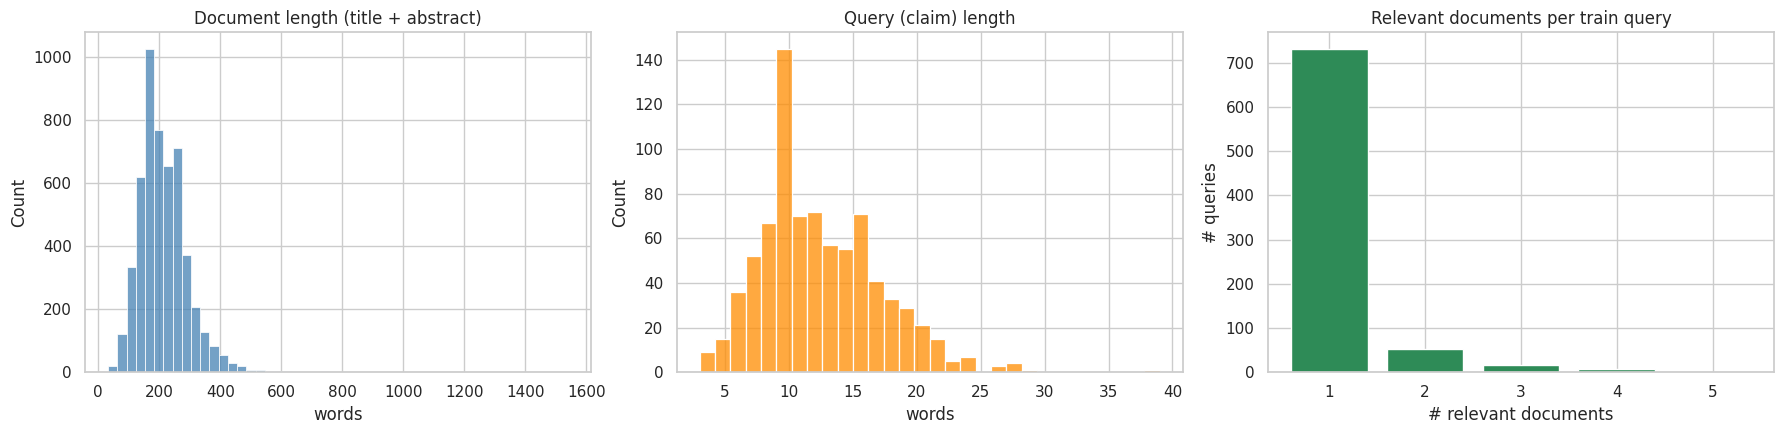


--- Example positive query-document pairs (from training qrels) ---
[0 -> 31715818] relevance=1
  QUERY  : 0-dimensional biomaterials lack inductive properties.
  PASSAGE: New opportunities: the use of nanotechnologies to manipulate and track stem cells.. Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo track ...

[2 -> 13734012] relevance=1
  QUERY  : 1 in 5 million in UK have abnormal PrP positivity.
  PASSAGE: Prevalent abnormal prion protein in human appendixes after bovine spongiform encephalopathy epizootic: large scale survey. OBJECTIVES To carry out a further survey of archived appendix samples to understand better the differences between existing estimates of the prevalence of subclinical infection  ...

[4 -> 22942787] relevance=1
  QUERY  : 1-1% of colorectal cancer patients are diagnosed with regional or distant m

In [31]:
def passage_text(doc: dict) -> str:
    """Combine title and abstract into the passage the model reads."""
    title = (doc.get("title") or "").strip()
    text = (doc.get("text") or "").strip()
    return f"{title}. {text}" if title and text else (title or text)


# Lengths in whitespace-separated words (a rough, tokenizer-independent measure)
doc_lengths = pd.Series([len(passage_text(d).split()) for d in corpus.values()])
query_lengths = pd.Series([len(q.split()) for q in train_queries_all.values()])
judgments_per_query = pd.Series({qid: sum(1 for s in docs.values() if s > 0) for qid, docs in train_qrels_all.items()})
queries_with_relevant = int((judgments_per_query > 0).sum())

stats_table = pd.DataFrame({
    "Passage length (words)": doc_lengths.describe(),
    "Query length (words)": query_lengths.describe(),
    "Relevant docs per train query": judgments_per_query.describe(),
}).round(2)
display(stats_table)
print(f"Train queries with at least one relevant document: {queries_with_relevant} / {len(train_queries_all)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(doc_lengths, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Document length (title + abstract)")
axes[0].set_xlabel("words")
sns.histplot(query_lengths, bins=30, ax=axes[1], color="darkorange")
axes[1].set_title("Query (claim) length")
axes[1].set_xlabel("words")
counts = judgments_per_query.value_counts().sort_index()
axes[2].bar(counts.index.astype(str), counts.values, color="seagreen")
axes[2].set_title("Relevant documents per train query")
axes[2].set_xlabel("# relevant documents")
axes[2].set_ylabel("# queries")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n--- Example positive query-document pairs (from training qrels) ---")
shown = 0
for qid, docs in train_qrels_all.items():
    for did, score in docs.items():
        if score > 0 and did in corpus:
            print(f"[{qid} -> {did}] relevance={score}")
            print("  QUERY  :", train_queries_all[qid])
            print("  PASSAGE:", passage_text(corpus[did])[:300], "...\n")
            shown += 1
            break
    if shown >= 3:
        break

### Observations

Read the printed statistics and plots above rather than any fixed numbers quoted here. Things to check:

* **Passages are abstracts**, typically far longer than the queries, which are short single-sentence scientific *claims* rather than keyword searches. A 512-token limit should cover most abstracts; the length histogram shows how many are long enough to be truncated.
* **Few judgments per query.** Most queries have only a small number of relevant documents, so the number of positive training pairs is limited. This is a *small* fine-tuning set, which makes overfitting a real risk (we monitor it with a validation set).
* **Labels are sparse.** A document that is not listed for a query is *unjudged*, which is not the same as *irrelevant*. We keep this in mind when mining negatives.

# 6. Prepare Positive Training Pairs

For retrieval, the **qrels** tell us which documents are relevant to each query. Every `(query_id, doc_id)` entry with relevance score `> 0` becomes one **positive pair** with `label = 1`. The passage is `title + abstract`.

> **Important – stance is not relevance.** SciFact's *original* annotations also record whether an abstract **supports** or **refutes** a claim. In the BEIR version those stances are collapsed into a single relevance judgment, and we use only that. A passage that *contradicts* a claim is still highly relevant for retrieval (a scientist wants to see it), so we never treat "refutes" as "irrelevant".

Only the **official train qrels** are used here. The test qrels are not touched.

In [32]:
positive_rows = []
skipped_missing = 0

for qid, doc_scores in train_qrels_all.items():
    if qid not in train_queries_all:
        skipped_missing += 1
        continue
    for did, score in doc_scores.items():
        if score <= 0:                 # only positively judged documents are positives
            continue
        if did not in corpus:          # defensive: skip judgments pointing at missing documents
            skipped_missing += 1
            continue
        positive_rows.append({
            "query_id": qid,
            "document_id": did,
            "query": train_queries_all[qid],
            "passage": passage_text(corpus[did]),
            "label": 1,
            "source": "qrels_positive",
            "bm25_rank": -1,
        })

positive_df = pd.DataFrame(positive_rows)
print(f"Positive pairs: {len(positive_df):,} | queries covered: {positive_df['query_id'].nunique():,} | "
      f"skipped (missing ids): {skipped_missing}")
print("\nExample positive pair:")
print(json.dumps(positive_df.iloc[0][["query_id", "document_id", "query", "passage", "label"]].to_dict(),
                 indent=2)[:900])

Positive pairs: 919 | queries covered: 809 | skipped (missing ids): 0

Example positive pair:
{
  "query_id": "0",
  "document_id": "31715818",
  "query": "0-dimensional biomaterials lack inductive properties.",
  "passage": "New opportunities: the use of nanotechnologies to manipulate and track stem cells.. Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotubes, and polyplexes for the intracellular delivery of genes/oligonucleotides and protein/peptides; and engineered nanometer-scale scaffolds for stem cell differentiation and transplantation. This review examines the use of nanotechnologies for stem cell tracking, differentiation, and transplantation. We further discuss their utility and the potential concerns regarding their cytotoxicity.",
  "label": 1
}


# 7. Generate Hard Negative Examples

## What are hard negatives, and why not random ones?
A **negative** is a passage that should get a *low* score for a query. A **random** negative (e.g. a passage about oceans for a vitamin-D query) is *too easy*: the model learns nothing by separating it. At test time, the difficult competitors are passages that are **topically similar** but not actually relevant. **Hard negatives** are exactly those: passages that a first-stage retriever ranks highly even though they are not judged relevant. Training against them forces the cross-encoder to learn finer distinctions, which is what reranking is for.

## Mining procedure (BM25)
1. Build a **BM25** index over the SciFact corpus (lexical retrieval; `rank_bm25`).
2. For every **official-train** query, retrieve the top candidates.
3. Remove every document that has *any* judgment for that query (positives, plus anything judged).
4. Remove duplicates.
5. Keep the highest-ranked remaining candidates (`hard_negatives_per_positive` × number of positives for that query).
6. Store `query_id`, `document_id` and `bm25_rank` for traceability.

## Data-quality rules
* **Unjudged ≠ irrelevant.** BM25 may retrieve a document that really is relevant but was never annotated. These are **provisional negatives** (label noise is possible). We inspect a sample below.
* Only **train** queries are used for mining. Test queries are never retrieved for, and test qrels are never read here.
* A note on the shared corpus: SciFact's corpus is shared between splits, so a document that is relevant to a *test* query can legitimately appear as an unjudged negative for a *train* query. Using test qrels to filter that out would itself be leakage, so we do not. This is a small, documented limitation.

In [33]:
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

TOKEN_PATTERN = re.compile(r"\w+")


def bm25_tokenize(text: str) -> list:
    """Lowercase, split on word characters, drop English stop-words."""
    return [tok for tok in TOKEN_PATTERN.findall(text.lower()) if tok not in ENGLISH_STOP_WORDS]


def build_bm25_index(corpus_dict: dict):
    """Return (bm25_index, list_of_doc_ids) for a BEIR corpus."""
    doc_ids = list(corpus_dict.keys())
    tokenized = [bm25_tokenize(passage_text(corpus_dict[d])) for d in tqdm(doc_ids, desc="Tokenizing corpus")]
    return BM25Okapi(tokenized), doc_ids


def bm25_retrieve(bm25_index, doc_ids, query_dict: dict, top_k: int, drop_self_match: bool = False) -> dict:
    """Return {query_id: [doc_ids ranked by BM25, best first]} limited to top_k."""
    results = {}
    for qid, qtext in tqdm(query_dict.items(), desc="BM25 retrieval"):
        scores = bm25_index.get_scores(bm25_tokenize(qtext))
        k = min(top_k + 1 if drop_self_match else top_k, len(scores))
        top_idx = np.argpartition(-scores, k - 1)[:k]
        top_idx = top_idx[np.argsort(-scores[top_idx], kind="stable")]
        ranked = [doc_ids[i] for i in top_idx]
        if drop_self_match:                      # used for SCIDOCS where the query paper is also in the corpus
            ranked = [d for d in ranked if d != qid]
        results[qid] = ranked[:top_k]
    return results


scifact_bm25, scifact_doc_ids = build_bm25_index(corpus)

# Retrieve once for all official-TRAIN queries: top-100 is used for mining (top-N) and for validation pools.
train_bm25_results = bm25_retrieve(scifact_bm25, scifact_doc_ids, train_queries_all, top_k=CONFIG["rerank_depth"])
print("Retrieved BM25 candidates for", len(train_bm25_results), "official-train queries")

Tokenizing corpus:   0%|          | 0/5183 [00:00<?, ?it/s]

BM25 retrieval:   0%|          | 0/809 [00:00<?, ?it/s]

Retrieved BM25 candidates for 809 official-train queries


In [34]:
hard_negative_rows = []

for qid, ranked_docs in train_bm25_results.items():
    positives = {d for d, s in train_qrels_all.get(qid, {}).items() if s > 0}
    if not positives:
        continue
    already_judged = set(train_qrels_all[qid].keys())          # positives and any other judged docs
    n_wanted = CONFIG["hard_negatives_per_positive"] * len(positives)

    selected = set()
    for rank, did in enumerate(ranked_docs[:CONFIG["bm25_mining_depth"]], start=1):
        if did in already_judged or did in selected:           # never use judged docs; no duplicates
            continue
        selected.add(did)
        hard_negative_rows.append({
            "query_id": qid,
            "document_id": did,
            "query": train_queries_all[qid],
            "passage": passage_text(corpus[did]),
            "label": 0,
            "source": "bm25_hard_negative",
            "bm25_rank": rank,
        })
        if len(selected) >= n_wanted:
            break

hard_negative_df = pd.DataFrame(hard_negative_rows)

# ---------- Safety checks ----------
assert set(hard_negative_df["query_id"]).issubset(set(train_queries_all)), "Negatives must come from train queries"
assert set(hard_negative_df["query_id"]).isdisjoint(set(test_queries)), "Test queries leaked into mining"
merged_check = hard_negative_df.merge(positive_df[["query_id", "document_id"]], on=["query_id", "document_id"], how="inner")
assert len(merged_check) == 0, "A known positive was selected as a negative"
assert not hard_negative_df.duplicated(["query_id", "document_id"]).any(), "Duplicate negatives found"

print(f"Positive pairs      : {len(positive_df):,}")
print(f"Hard-negative pairs : {len(hard_negative_df):,}")
print(f"Positive : negative ratio = 1 : {len(hard_negative_df) / len(positive_df):.2f}")
print("BM25 rank of selected negatives:")
display(hard_negative_df["bm25_rank"].describe().round(1).to_frame().T)

print("\n--- Example positive pair ---")
ex_pos = positive_df.iloc[0]
print("QUERY  :", ex_pos["query"])
print("PASSAGE:", ex_pos["passage"][:300], "...")

print("\n--- Example hard-negative pair (same query) ---")
ex_neg = hard_negative_df[hard_negative_df["query_id"] == ex_pos["query_id"]].iloc[0]
print("QUERY  :", ex_neg["query"])
print(f"PASSAGE (BM25 rank {ex_neg['bm25_rank']}): {ex_neg['passage'][:300]} ...")

print("\n--- Manual inspection: 4 random hard negatives (are any obviously relevant?) ---")
for _, row in hard_negative_df.sample(4, random_state=SEED).iterrows():
    print(f"[{row['query_id']} / {row['document_id']}] BM25 rank {row['bm25_rank']}")
    print("  QUERY  :", row["query"])
    print("  NEG    :", row["passage"][:220], "...\n")

Positive pairs      : 919
Hard-negative pairs : 2,757
Positive : negative ratio = 1 : 3.00
BM25 rank of selected negatives:


,count,mean,std,min,25%,50%,75%,max
bm25_rank,2757.0,3.3,2.2,1.0,2.0,3.0,4.0,18.0



--- Example positive pair ---
QUERY  : 0-dimensional biomaterials lack inductive properties.
PASSAGE: New opportunities: the use of nanotechnologies to manipulate and track stem cells.. Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo track ...

--- Example hard-negative pair (same query) ---
QUERY  : 0-dimensional biomaterials lack inductive properties.
PASSAGE (BM25 rank 1): High-performance neuroprosthetic control by an individual with tetraplegia.. BACKGROUND Paralysis or amputation of an arm results in the loss of the ability to orient the hand and grasp, manipulate, and carry objects, functions that are essential for activities of daily living. Brain-machine interfa ...

--- Manual inspection: 4 random hard negatives (are any obviously relevant?) ---
[1404 / 6550579] BM25 rank 7
  QUERY  : siRNA knockdown of A20 slows t

# 8. Create the Training and Validation Splits

We split at the **query level**: we randomly assign whole *queries* to train or validation with a fixed seed, and **every pair (positive and negative) of a query goes to the same side**.

**Why not split individual pairs?** If pairs were split randomly, the *same query* would appear in both train and validation (with different passages). The model could then memorize query-specific patterns, validation loss would look better than it should, and we would be unable to detect overfitting. Query-level splitting prevents this leakage.

The **official SciFact test split is left completely untouched**: it was loaded in Section 4 but nothing derived from it has been used.

We save `train_pairs.csv` and `validation_pairs.csv`.

In [35]:
from sklearn.model_selection import train_test_split

all_pair_df = pd.concat([positive_df, hard_negative_df], ignore_index=True)
query_ids_with_positives = sorted(positive_df["query_id"].unique())

train_qids, val_qids = train_test_split(
    query_ids_with_positives,
    test_size=CONFIG["validation_fraction"],
    random_state=SEED,
    shuffle=True,
)
train_qid_set, val_qid_set = set(train_qids), set(val_qids)

# Shuffle training pairs once (DataLoader reshuffles every epoch anyway); keep validation order deterministic.
train_df = all_pair_df[all_pair_df["query_id"].isin(train_qid_set)].sample(frac=1.0, random_state=SEED).reset_index(drop=True)
val_df = all_pair_df[all_pair_df["query_id"].isin(val_qid_set)].reset_index(drop=True)

# ---------- Leakage checks ----------
assert train_qid_set.isdisjoint(val_qid_set), "A query appears in both train and validation"
assert set(train_df["query_id"]).isdisjoint(set(val_df["query_id"])), "Pairs of one query are split across train/val"
assert (train_qid_set | val_qid_set).isdisjoint(set(test_queries)), "Official test queries found in train/val"

print(f"Train queries      : {len(train_qid_set):,} | pairs: {len(train_df):,} "
      f"(positives {int(train_df['label'].sum()):,}, negatives {int((train_df['label'] == 0).sum()):,})")
print(f"Validation queries : {len(val_qid_set):,} | pairs: {len(val_df):,} "
      f"(positives {int(val_df['label'].sum()):,}, negatives {int((val_df['label'] == 0).sum()):,})")

train_df.to_csv(DATA_DIR / "train_pairs.csv", index=False)
val_df.to_csv(DATA_DIR / "validation_pairs.csv", index=False)
print("Saved:", DATA_DIR / "train_pairs.csv", "and", DATA_DIR / "validation_pairs.csv")

Train queries      : 687 | pairs: 3,136 (positives 784, negatives 2,352)
Validation queries : 122 | pairs: 540 (positives 135, negatives 405)
Saved: /kaggle/working/researchnexus-finetuning/datasets/train_pairs.csv and /kaggle/working/researchnexus-finetuning/datasets/validation_pairs.csv


# 9. Build a PyTorch Dataset

## Tokenization
A Transformer cannot read text; it reads integer **token IDs**. The tokenizer converts a *pair* of texts into one sequence:

```
[CLS] query tokens [SEP] passage tokens [SEP]
```

It returns:

* **`input_ids`** – the integer token IDs.
* **`attention_mask`** – 1 for real tokens, 0 for padding. Batches need equal-length rows, so shorter sequences are padded; the mask tells self-attention to **ignore** padded positions.
* **`token_type_ids`** – 0 for the query segment, 1 for the passage segment (BERT-family models use this to tell the two texts apart; we pass it to the model as well).

We truncate to a maximum of **512 tokens**. For efficiency the `Dataset` tokenizes each item (with truncation) and a **collate function** pads each batch only to the length of its longest member (*dynamic padding*), which is equivalent to padding but much faster than padding everything to 512.

Each item also carries the **label** (1 = relevant, 0 = hard negative) as a float, as required by `BCEWithLogitsLoss`.

In [36]:
class QueryPassageDataset(Dataset):
    """Tokenizes (query, passage) pairs as one sequence: [CLS] query [SEP] passage [SEP]."""

    def __init__(self, pairs: pd.DataFrame, tokenizer, max_length: int):
        self.queries = pairs["query"].tolist()
        self.passages = pairs["passage"].tolist()
        self.labels = pairs["label"].astype("float32").tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> dict:
        encoded = self.tokenizer(
            self.queries[index],
            self.passages[index],
            truncation=True,                 # cut the sequence at max_length tokens
            max_length=self.max_length,
        )
        item = {"input_ids": encoded["input_ids"], "attention_mask": encoded["attention_mask"]}
        if "token_type_ids" in encoded:
            item["token_type_ids"] = encoded["token_type_ids"]
        item["labels"] = self.labels[index]
        return item


def make_collate_fn(tokenizer):
    """Pad every sequence in a batch to the longest one and build tensors."""

    def collate(batch: list) -> dict:
        labels = torch.tensor([item["labels"] for item in batch], dtype=torch.float32)
        features = [{k: v for k, v in item.items() if k != "labels"} for item in batch]
        padded = dict(tokenizer.pad(features, padding=True, return_tensors="pt"))
        padded["labels"] = labels
        return padded

    return collate


collate_fn = make_collate_fn(tokenizer)
train_dataset = QueryPassageDataset(train_df, tokenizer, CONFIG["max_length"])
val_dataset = QueryPassageDataset(val_df, tokenizer, CONFIG["max_length"])

train_generator = torch.Generator().manual_seed(SEED)    # reproducible shuffling
train_loader = DataLoader(
    train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, generator=train_generator,
    collate_fn=collate_fn, num_workers=2, pin_memory=USE_AMP,
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,        # never shuffle validation
    collate_fn=collate_fn, num_workers=2, pin_memory=USE_AMP,
)

# ---------- Sanity check before training ----------
sample_batch = next(iter(train_loader))
print("Batch keys    :", list(sample_batch.keys()))
for key, value in sample_batch.items():
    print(f"  {key:15s} shape={tuple(value.shape)} dtype={value.dtype}")
print("Labels in batch:", sample_batch["labels"].tolist())
print("Padding tokens in first row:", int((sample_batch["attention_mask"][0] == 0).sum()))
print("\nDecoded first example:\n", tokenizer.decode(sample_batch["input_ids"][0][:80]), "...")
print(f"\nTrain batches per epoch: {len(train_loader)} | Validation batches: {len(val_loader)}")

Batch keys    : ['input_ids', 'attention_mask', 'token_type_ids', 'labels']
  input_ids       shape=(16, 512) dtype=torch.int64
  attention_mask  shape=(16, 512) dtype=torch.int64
  token_type_ids  shape=(16, 512) dtype=torch.int64
  labels          shape=(16,) dtype=torch.float32
Labels in batch: [1.0, 0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0]
Padding tokens in first row: 205

Decoded first example:
 [CLS] activated cdk5 phosphorylates the atm protein in response to dna damage. [SEP] phosphorylation of atm by cdk5 mediates dna damage signaling and regulates neuronal death. the phosphatidylinositol - 3 - kinase - like kinase atm ( ataxia - telangiectasia mutated ) has a central role in coordinating dna damage ...

Train batches per epoch: 196 | Validation batches: 34


# 10. Evaluate the Pretrained Baseline

Before fine-tuning we must know how good the **original** model already is; otherwise we cannot say whether fine-tuning helped.

## Evaluation protocol (identical for every model and dataset)
1. For each held-out query, take a **fixed candidate pool**: the **top-100 BM25** documents (computed once, reused for both models).
2. The cross-encoder scores every `(query, candidate)` pair and the candidates are **re-sorted** by score.
3. Metrics are computed against the **qrels** (positive judgments). Queries with no relevant document are skipped. Relevant documents that BM25 did not retrieve into the pool cannot be recovered by reranking and therefore count against recall – we report the pool's recall@100 as the upper bound.

## Metrics
* **Precision@5** – of the top 5 results, the fraction that are relevant.
* **Recall@5** – of all relevant documents for the query, the fraction found in the top 5.
* **MRR@5** (Mean Reciprocal Rank) – `1 / rank` of the first relevant result within the top 5 (0 if none), averaged over queries. Rewards putting *one* correct answer very high.
* **nDCG@10** (normalized Discounted Cumulative Gain) – each relevant result earns `1 / log2(rank + 1)`, so higher ranks count more; divided by the best achievable score, so the result lies between 0 and 1. Rewards ranking *all* relevant results near the top.

Relevance here is **binary** (score > 0).

In [37]:
K_PRECISION, K_RECALL, K_MRR, K_NDCG = 5, 5, 5, 10
METRIC_NAMES = ["MRR@5", "Recall@5", "nDCG@10", "Precision@5"]


def compute_ranking_metrics(rankings: dict, qrels: dict):
    """rankings: {query_id: [doc_ids best-first]}; qrels: {query_id: {doc_id: score}}.
    Returns (summary dict of means, per-query DataFrame). Queries without a relevant doc are skipped."""
    per_query = []
    for qid, ranked in rankings.items():
        relevant = {d for d, s in qrels.get(qid, {}).items() if s > 0}
        if not relevant:
            continue
        hits_at_5 = sum(1 for d in ranked[:K_PRECISION] if d in relevant)

        reciprocal_rank = 0.0
        for rank, did in enumerate(ranked[:K_MRR], start=1):
            if did in relevant:
                reciprocal_rank = 1.0 / rank
                break

        dcg = sum(1.0 / math.log2(rank + 1) for rank, did in enumerate(ranked[:K_NDCG], start=1) if did in relevant)
        ideal_dcg = sum(1.0 / math.log2(rank + 1) for rank in range(1, min(len(relevant), K_NDCG) + 1))

        per_query.append({
            "query_id": qid,
            "MRR@5": reciprocal_rank,
            "Recall@5": hits_at_5 / len(relevant),
            "nDCG@10": dcg / ideal_dcg,
            "Precision@5": hits_at_5 / K_PRECISION,
        })
    per_query_df = pd.DataFrame(per_query)
    summary = {name: float(per_query_df[name].mean()) for name in METRIC_NAMES}
    summary["num_queries"] = int(len(per_query_df))
    return summary, per_query_df


def pool_recall(pools: dict, qrels: dict, depth: int) -> float:
    """Upper bound for reranking: mean fraction of relevant docs present in the candidate pool."""
    values = []
    for qid, docs in pools.items():
        relevant = {d for d, s in qrels.get(qid, {}).items() if s > 0}
        if relevant:
            values.append(len(relevant & set(docs[:depth])) / len(relevant))
    return float(np.mean(values))


@torch.no_grad()
def score_pairs(model, tok, query_texts: list, passage_texts: list, batch_size: int, max_length: int, desc: str = "Scoring"):
    """Return one relevance logit per (query, passage) pair. Pairs are processed sorted by length for speed."""
    model.eval()
    device = next(model.parameters()).device
    use_amp = device.type == "cuda"
    order = np.argsort([len(p) for p in passage_texts], kind="stable")
    scores = np.zeros(len(passage_texts), dtype=np.float32)
    for start in tqdm(range(0, len(order), batch_size), desc=desc, leave=False):
        idx = order[start:start + batch_size]
        enc = tok([query_texts[i] for i in idx], [passage_texts[i] for i in idx],
                  truncation=True, max_length=max_length, padding=True, return_tensors="pt").to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(**enc).logits
        scores[idx] = logits.squeeze(-1).float().cpu().numpy()
    return scores


def rerank_pools(model, tok, pools: dict, query_dict: dict, corpus_dict: dict, depth: int, desc: str):
    """Score the top-`depth` candidates of every pool and return {query_id: [doc_ids best-first]}."""
    keys, q_texts, p_texts = [], [], []
    for qid, docs in pools.items():
        for did in docs[:depth]:
            keys.append((qid, did))
            q_texts.append(query_dict[qid])
            p_texts.append(passage_text(corpus_dict[did]))
    scores = score_pairs(model, tok, q_texts, p_texts, CONFIG["eval_batch_size"], CONFIG["max_length"], desc)
    grouped = defaultdict(list)
    for (qid, did), score in zip(keys, scores):
        grouped[qid].append((did, float(score)))
    # sorted() is stable, so ties keep their BM25 order
    return {qid: [d for d, _ in sorted(items, key=lambda x: -x[1])] for qid, items in grouped.items()}


# ---------- Held-out validation queries and their FIXED candidate pools ----------
val_queries = {qid: train_queries_all[qid] for qid in val_qids}
val_qrels = {qid: train_qrels_all[qid] for qid in val_qids}
val_pools = {qid: train_bm25_results[qid][:CONFIG["rerank_depth"]] for qid in val_qids}

print(f"Validation queries: {len(val_queries)} | candidates per query: {CONFIG['rerank_depth']}")
print(f"Candidate-pool recall@{CONFIG['rerank_depth']} (upper bound for any reranker): "
      f"{pool_recall(val_pools, val_qrels, CONFIG['rerank_depth']):.4f}")

ALL_RESULTS = {}      # every measured metric dict is stored here, keyed by (model, dataset-split)

# First-stage BM25 ordering as a reference point
bm25_val_metrics, _ = compute_ranking_metrics(val_pools, val_qrels)
ALL_RESULTS[("BM25 (first stage)", "SciFact validation")] = bm25_val_metrics

# ---------- Pretrained baseline ----------
pretrained_model.to(DEVICE).eval()
pretrained_val_rankings = rerank_pools(pretrained_model, tokenizer, val_pools, val_queries, corpus,
                                       CONFIG["rerank_depth"], "Pretrained: validation")
baseline_metrics, baseline_per_query = compute_ranking_metrics(pretrained_val_rankings, val_qrels)
ALL_RESULTS[("Pretrained MiniLM", "SciFact validation")] = baseline_metrics

baseline_df = pd.DataFrame([{"Model": "Pretrained MiniLM", "Dataset": "SciFact validation", **baseline_metrics}])
baseline_df.to_csv(RESULTS_DIR / "baseline_metrics.csv", index=False)
display(pd.DataFrame([bm25_val_metrics, baseline_metrics], index=["BM25 first stage", "Pretrained MiniLM"]).round(4))

Validation queries: 122 | candidates per query: 100
Candidate-pool recall@100 (upper bound for any reranker): 0.9160


Pretrained: validation:   0%|          | 0/191 [00:00<?, ?it/s]

,MRR@5,Recall@5,nDCG@10,Precision@5,num_queries
BM25 first stage,0.6064,0.6633,0.6513,0.1426,122
Pretrained MiniLM,0.6350,0.7637,0.6746,0.1656,122


# 11. Configure PyTorch Fine-Tuning

**Fine-tuning** continues training from the pretrained weights – we load the model into a *new* object so the original folder stays unchanged – and update **all** parameters with a small learning rate on our SciFact pairs.

## Concepts
* **Binary cross-entropy with logits (`BCEWithLogitsLoss`).** For a logit `z` and label `y ∈ {0,1}`: `loss = -[ y·log σ(z) + (1-y)·log(1-σ(z)) ]`, where `σ` is the sigmoid. The loss is small when the model is confident *and correct*, large when confident and wrong. The "WithLogits" version applies the sigmoid **internally** in a numerically stable way, so we must pass **raw logits** and **must not apply sigmoid ourselves first**.
* **Why one logit?** We saw `num_labels = 1` in Section 3: the head outputs a single relevance score per pair. The output is `[batch, 1]`; we `squeeze(-1)` it to `[batch]` to match the `[batch]` label vector.
* **Backpropagation.** `loss.backward()` computes the gradient of the loss with respect to every parameter; the **optimizer** (`AdamW`) uses these gradients to nudge the weights; `optimizer.zero_grad()` clears the gradients before the next batch.
* **Learning rate (2e-5).** The step size of each weight update. Too large destroys pretrained knowledge; too small learns nothing. We use a **linear warm-up** (LR rises from 0 during the first 10% of steps) followed by a linear decay.
* **Weight decay (0.01).** Mild regularization (applied to weights, not to biases and LayerNorm parameters).
* **Gradient clipping.** If the gradient norm exceeds 1.0 it is rescaled, which prevents occasional huge updates.
* **Mixed precision (FP16).** On a CUDA GPU, `torch.autocast` runs most operations in half precision for speed and memory; a `GradScaler` rescales the loss so tiny fp16 gradients do not underflow. Disabled automatically on CPU.
* **Out-of-memory handling.** If a batch causes a CUDA OOM error, the training step retries it as two half-size micro-batches; if that also fails it stops with an explicit message (no silent skipping).
* **Overfitting.** The model memorizes training data and gets worse on unseen data. Symptom: training loss keeps falling while **validation** loss rises. We therefore select the best checkpoint by *validation* loss and use early stopping.

| Parameter | Value |
|---|---:|
| Epochs | 3 |
| Learning rate | 2e-5 |
| Batch size | 16 |
| Gradient accumulation | 1 |
| Maximum sequence length | 512 |
| Weight decay | 0.01 |
| Optimizer | AdamW |
| Loss | BCEWithLogitsLoss |
| Precision | FP16 when supported |

In [38]:
set_seed(SEED)

# A NEW model object loaded from the untouched pretrained folder. Its weights will be updated;
# the checkpoint on disk (PRETRAINED_DIR) is never modified.
finetune_model = AutoModelForSequenceClassification.from_pretrained(PRETRAINED_DIR).to(DEVICE)

# Inspect the output shape BEFORE choosing the loss
finetune_model.eval()
with torch.no_grad():
    probe_inputs = {k: v.to(DEVICE) for k, v in sample_batch.items() if k != "labels"}
    probe_logits = finetune_model(**probe_inputs).logits
print("Logits shape :", tuple(probe_logits.shape), " -> squeezed:", tuple(probe_logits.squeeze(-1).shape))
print("Labels shape :", tuple(sample_batch["labels"].shape))
assert probe_logits.shape[-1] == 1, "Single-logit head expected"

loss_fn = nn.BCEWithLogitsLoss()   # takes RAW logits; do not apply sigmoid before it

# Weight decay on weights only (not on biases / LayerNorm)
no_decay_keywords = ["bias", "LayerNorm.weight", "LayerNorm.bias"]
grouped_parameters = [
    {"params": [p for n, p in finetune_model.named_parameters() if not any(k in n for k in no_decay_keywords)],
     "weight_decay": CONFIG["weight_decay"]},
    {"params": [p for n, p in finetune_model.named_parameters() if any(k in n for k in no_decay_keywords)],
     "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(grouped_parameters, lr=CONFIG["learning_rate"])

steps_per_epoch = math.ceil(len(train_loader) / CONFIG["gradient_accumulation_steps"])
total_optimizer_steps = steps_per_epoch * CONFIG["epochs"]
warmup_steps = int(CONFIG["warmup_ratio"] * total_optimizer_steps)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps,
                                            num_training_steps=total_optimizer_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print(f"Optimizer steps per epoch: {steps_per_epoch} | total: {total_optimizer_steps} | warm-up steps: {warmup_steps}")
print(f"Device: {DEVICE} | FP16 autocast: {USE_AMP}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Logits shape : (16, 1)  -> squeezed: (16,)
Labels shape : (16,)
Optimizer steps per epoch: 196 | total: 588 | warm-up steps: 58
Device: cuda | FP16 autocast: True


# 12. Implement the Training Loop

For every batch the loop does exactly these steps:

1. load a batch → 2. move tensors to the device → 3. forward pass → 4. take the relevance logits → 5. compute `BCEWithLogitsLoss` → 6. `loss.backward()` → 7. clip gradients, `optimizer.step()`, `scheduler.step()`, `optimizer.zero_grad()` → 8. record the loss.

After every epoch we compute the **validation loss** (`model.eval()` + `torch.no_grad()`), log epoch, losses, learning rate and duration, **save the checkpoint if validation loss improved**, and **stop early** if it has not improved for `early_stopping_patience` epochs.

Errors are never swallowed: a non-finite loss raises an exception, and an unrecoverable CUDA OOM raises with a clear instruction.

In [39]:
def compute_loss(model, batch: dict, loss_function, device, use_amp: bool):
    """Steps 2-5: move to device, forward pass, get relevance logits, compute BCE-with-logits."""
    inputs = {k: v.to(device, non_blocking=True) for k, v in batch.items() if k != "labels"}
    labels = batch["labels"].to(device, non_blocking=True)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        logits = model(**inputs).logits.squeeze(-1)          # [batch, 1] -> [batch]
    return loss_function(logits.float(), labels), logits      # loss computed in fp32 for stability


def split_batch(batch: dict, parts: int = 2) -> list:
    """Split a batch along the batch dimension (used only for the OOM fallback)."""
    chunks = {k: torch.chunk(v, parts) for k, v in batch.items()}
    return [{k: chunks[k][i] for k in chunks} for i in range(len(chunks["labels"]))]


def backward_with_oom_fallback(model, batch, loss_function, scaler_obj, device, use_amp, accumulation_steps) -> float:
    """Forward + backward for one batch. On CUDA OOM, retry as two micro-batches. Returns the batch loss."""
    try:
        loss, _ = compute_loss(model, batch, loss_function, device, use_amp)
        scaler_obj.scale(loss / accumulation_steps).backward()
        return loss.item()
    except torch.cuda.OutOfMemoryError:
        pass                                                  # handled below, outside the except block

    # --- OOM fallback (a failure in the FORWARD pass leaves existing gradients untouched) ---
    torch.cuda.empty_cache()
    print("[WARNING] CUDA out of memory - retrying this batch as two smaller micro-batches.")
    total = batch["labels"].shape[0]
    loss_value = 0.0
    for chunk in split_batch(batch, parts=2):
        fraction = chunk["labels"].shape[0] / total
        try:
            loss, _ = compute_loss(model, chunk, loss_function, device, use_amp)
            scaler_obj.scale(loss * fraction / accumulation_steps).backward()
            loss_value += loss.item() * fraction
        except torch.cuda.OutOfMemoryError as err:
            torch.cuda.empty_cache()
            raise RuntimeError(
                "CUDA out of memory even after splitting the batch. Lower CONFIG['batch_size'] or "
                "CONFIG['max_length'], then re-run from Section 9."
            ) from err
    return loss_value


def train_one_epoch(model, loader, optimizer_obj, scheduler_obj, scaler_obj, loss_function, device, use_amp,
                    accumulation_steps, max_grad_norm, epoch_number):
    model.train()
    running_loss, n_samples, lr_log = 0.0, 0, []
    optimizer_obj.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(loader, desc=f"Epoch {epoch_number}", leave=False), start=1):
        batch_size = batch["labels"].shape[0]
        batch_loss = backward_with_oom_fallback(model, batch, loss_function, scaler_obj, device, use_amp, accumulation_steps)
        if not math.isfinite(batch_loss):
            raise FloatingPointError(f"Non-finite training loss at epoch {epoch_number}, step {step}: {batch_loss}")
        running_loss += batch_loss * batch_size
        n_samples += batch_size

        if step % accumulation_steps == 0 or step == len(loader):
            scaler_obj.unscale_(optimizer_obj)                                   # so clipping sees true gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)    # gradient clipping
            scaler_obj.step(optimizer_obj)                                       # optimizer.step() (skipped on inf grads)
            scaler_obj.update()
            scheduler_obj.step()                                                 # warm-up / decay of the learning rate
            optimizer_obj.zero_grad(set_to_none=True)
            lr_log.append(scheduler_obj.get_last_lr()[0])
    return running_loss / n_samples, lr_log


@torch.no_grad()
def evaluate_loss(model, loader, loss_function, device, use_amp) -> float:
    """Mean validation loss over all validation pairs."""
    model.eval()
    total, n_samples = 0.0, 0
    for batch in loader:
        loss, _ = compute_loss(model, batch, loss_function, device, use_amp)
        batch_size = batch["labels"].shape[0]
        total += loss.item() * batch_size
        n_samples += batch_size
    return total / n_samples


def fit(model, train_loader_, val_loader_, optimizer_obj, scheduler_obj, scaler_obj, loss_function, config, device,
        use_amp, save_dir: Path):
    """Full training procedure with per-epoch validation, best-checkpoint saving and early stopping."""
    history, lr_log = [], []
    best_val_loss, best_epoch, epochs_without_improvement = float("inf"), 0, 0

    initial_val_loss = evaluate_loss(model, val_loader_, loss_function, device, use_amp)
    print(f"Validation loss BEFORE fine-tuning (pretrained weights): {initial_val_loss:.4f}")

    for epoch in range(1, config["epochs"] + 1):
        start_time = time.time()
        train_loss, epoch_lrs = train_one_epoch(
            model, train_loader_, optimizer_obj, scheduler_obj, scaler_obj, loss_function, device, use_amp,
            config["gradient_accumulation_steps"], config["max_grad_norm"], epoch)
        val_loss = evaluate_loss(model, val_loader_, loss_function, device, use_amp)
        duration = time.time() - start_time
        lr_log.extend(epoch_lrs)

        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "learning_rate": epoch_lrs[-1], "duration_sec": duration})
        print(f"Epoch {epoch}/{config['epochs']} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"lr {epoch_lrs[-1]:.2e} | {duration:.1f}s")

        if val_loss < best_val_loss - config["early_stopping_min_delta"]:
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            model.save_pretrained(save_dir)                  # best checkpoint so far (weights + config)
            print(f"   -> validation loss improved; best checkpoint saved to {save_dir}")
        else:
            epochs_without_improvement += 1
            print(f"   -> no improvement for {epochs_without_improvement} epoch(s)")
            if epochs_without_improvement >= config["early_stopping_patience"]:
                print(f"Early stopping at epoch {epoch}.")
                break

    if best_epoch == 0:      # every epoch failed to beat the (infinite) initial best - cannot happen unless losses are NaN
        raise RuntimeError("No checkpoint was saved; check the loss values above.")
    return pd.DataFrame(history), lr_log, best_epoch, best_val_loss, initial_val_loss


training_start = time.time()
history_df, lr_per_step, best_epoch, best_val_loss, initial_val_loss = fit(
    finetune_model, train_loader, val_loader, optimizer, scheduler, scaler, loss_fn,
    CONFIG, DEVICE, USE_AMP, FINETUNED_DIR)
total_training_seconds = time.time() - training_start

print(f"\nBest epoch: {best_epoch} | best validation loss: {best_val_loss:.4f} | total time: {total_training_seconds / 60:.1f} min")
display(history_df.round(6))

Validation loss BEFORE fine-tuning (pretrained weights): 1.0951


Epoch 1:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.5909 | val loss 0.4746 | lr 1.48e-05 | 19.3s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> validation loss improved; best checkpoint saved to /kaggle/working/researchnexus-finetuning/minilm-scifact-finetuned


Epoch 2:   0%|          | 0/196 [00:00<?, ?it/s]

... (4 outputs left out)

Epoch 3/3 | train loss 0.3515 | val loss 0.4467 | lr 0.00e+00 | 19.6s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> validation loss improved; best checkpoint saved to /kaggle/working/researchnexus-finetuning/minilm-scifact-finetuned

Best epoch: 3 | best validation loss: 0.4467 | total time: 1.3 min


,epoch,train_loss,val_loss,learning_rate,duration_sec
0,1,0.590945,0.474628,0.000015,19.273688
1,2,0.409682,0.447075,0.000007,19.430159
2,3,0.351453,0.446700,0.000000,19.634995


# 13. Visualize Training Results

We plot the **training loss**, the **validation loss** and the **learning-rate schedule** (warm-up then linear decay).

How to read the plots:

* Falling **training** loss only shows the model fits the training pairs.
* **Validation** loss on unseen queries is the evidence of real learning. If training loss falls while validation loss rises, the model is overfitting.
* Loss values alone do not prove better *ranking*. A model can have lower BCE loss but not rank better, so the real verdict comes from the ranking metrics in Sections 15–17.

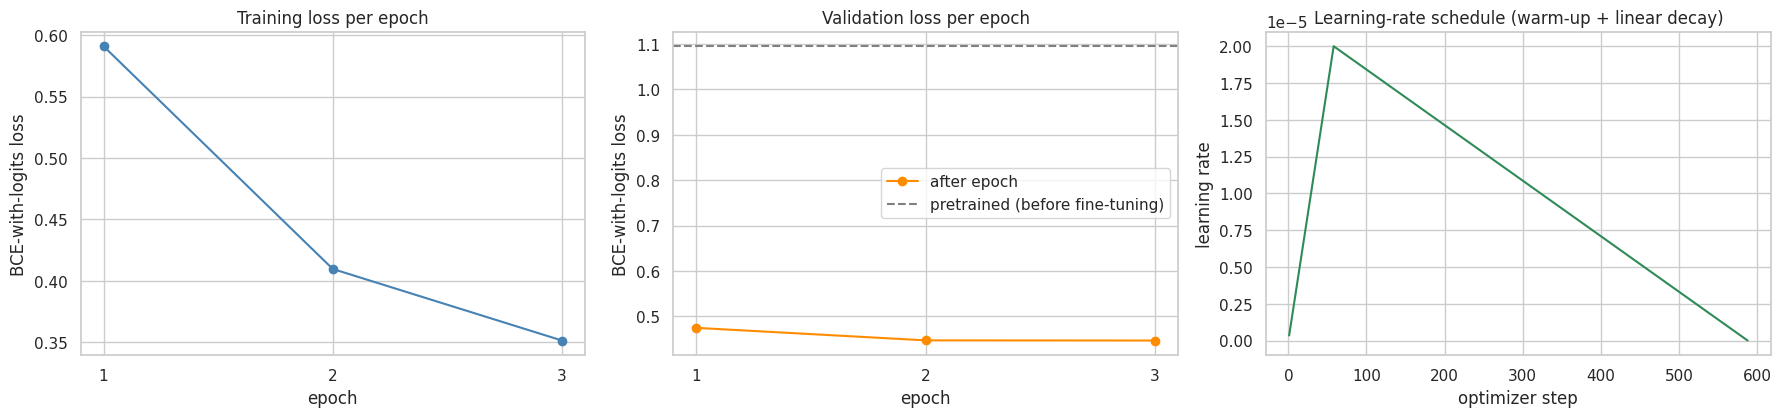

Validation loss: pretrained 1.0951 -> epoch 1 0.4746 -> last epoch 0.4467 (best 0.4467 at epoch 3)
Validation loss improved relative to the pretrained weights.
Final (validation - training) loss gap: 0.0952


In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", color="steelblue")
axes[0].set_title("Training loss per epoch")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("BCE-with-logits loss")
axes[0].set_xticks(history_df["epoch"])

axes[1].plot(history_df["epoch"], history_df["val_loss"], marker="o", color="darkorange", label="after epoch")
axes[1].axhline(initial_val_loss, color="gray", linestyle="--", label="pretrained (before fine-tuning)")
axes[1].set_title("Validation loss per epoch")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("BCE-with-logits loss")
axes[1].set_xticks(history_df["epoch"])
axes[1].legend()

axes[2].plot(range(1, len(lr_per_step) + 1), lr_per_step, color="seagreen")
axes[2].set_title("Learning-rate schedule (warm-up + linear decay)")
axes[2].set_xlabel("optimizer step")
axes[2].set_ylabel("learning rate")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

# Programmatic reading of the curves (no assumptions)
first_val, last_val = history_df["val_loss"].iloc[0], history_df["val_loss"].iloc[-1]
print(f"Validation loss: pretrained {initial_val_loss:.4f} -> epoch 1 {first_val:.4f} -> last epoch {last_val:.4f} "
      f"(best {best_val_loss:.4f} at epoch {best_epoch})")
print("Validation loss improved relative to the pretrained weights." if best_val_loss < initial_val_loss
      else "Validation loss did NOT improve relative to the pretrained weights.")
final_gap = history_df["val_loss"].iloc[-1] - history_df["train_loss"].iloc[-1]
print(f"Final (validation - training) loss gap: {final_gap:.4f}")
if len(history_df) > best_epoch:
    print("Validation loss rose after the best epoch -> possible onset of overfitting.")

# 14. Save the Fine-Tuned Model

The best checkpoint (lowest validation loss) was written to `minilm-scifact-finetuned/` during training. Here we reload it, add the tokenizer, the training configuration and the training history, and **verify** that the saved model reproduces the in-memory model's outputs.

The folder `minilm-pretrained/` is a different directory, so the original checkpoint stays unchanged. Evaluation results are added to the model folder in Sections 15–17.

In [41]:
# Reload the BEST checkpoint (training may have continued past the best epoch)
best_model = AutoModelForSequenceClassification.from_pretrained(FINETUNED_DIR).to(DEVICE).eval()

tokenizer.save_pretrained(FINETUNED_DIR)

training_config = {**CONFIG, "model_name": MODEL_NAME, "best_epoch": int(best_epoch),
                   "best_val_loss": float(best_val_loss), "initial_val_loss": float(initial_val_loss),
                   "total_training_seconds": float(total_training_seconds), "device": str(DEVICE),
                   "num_train_pairs": int(len(train_df)), "num_val_pairs": int(len(val_df)),
                   "num_train_queries": len(train_qid_set), "num_val_queries": len(val_qid_set)}
with open(FINETUNED_DIR / "training_config.json", "w") as f:
    json.dump(training_config, f, indent=2)

history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
history_df.to_csv(FINETUNED_DIR / "training_history.csv", index=False)

# ---------- Verify that the checkpoint reloads and matches the in-memory best weights ----------
verify_tokenizer = AutoTokenizer.from_pretrained(FINETUNED_DIR)
verify_model = AutoModelForSequenceClassification.from_pretrained(FINETUNED_DIR).to(DEVICE).eval()
verify_enc = verify_tokenizer(["vitamin D and bone health"] * 2, [demo_positive, demo_negative], padding=True,
                              truncation=True, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    logits_a = best_model(**verify_enc).logits
    logits_b = verify_model(**verify_enc).logits
assert torch.allclose(logits_a, logits_b, atol=1e-5), "Reloaded checkpoint does not reproduce the saved model"
print("Reload check passed: saved checkpoint reproduces identical logits.")

# The pretrained folder must still be the original model (different weights from the fine-tuned one)
print("\nFiles in", FINETUNED_DIR.name)
for file_path in sorted(FINETUNED_DIR.iterdir()):
    print(f"  {file_path.name:28s} {file_path.stat().st_size / 1024 ** 2:8.2f} MB")
del verify_model
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Reload check passed: saved checkpoint reproduces identical logits.

Files in minilm-scifact-finetuned
  config.json                      0.00 MB
  evaluation_results.json          0.00 MB
  model.safetensors               86.66 MB
  tokenizer.json                   0.68 MB
  tokenizer_config.json            0.00 MB
  training_config.json             0.00 MB
  training_history.csv             0.00 MB


# 15. Evaluate the Fine-Tuned Model

We now evaluate the fine-tuned model on **exactly the same validation queries and candidate pools** used for the pretrained baseline in Section 10, and compare the two with absolute and percentage changes.

> No result is assumed. If a metric did not improve, the table will show that.

Fine-tuned: validation:   0%|          | 0/191 [00:00<?, ?it/s]

Validation queries evaluated: 122 (same queries and pools for both models)


,Pretrained MiniLM,Fine-tuned MiniLM,Absolute change,Relative change (%)
MRR@5,0.6350,0.6663,0.0313,4.9269
Recall@5,0.7637,0.7964,0.0328,4.2934
nDCG@10,0.6746,0.7162,0.0417,6.1806
Precision@5,0.1656,0.1738,0.0082,4.9505


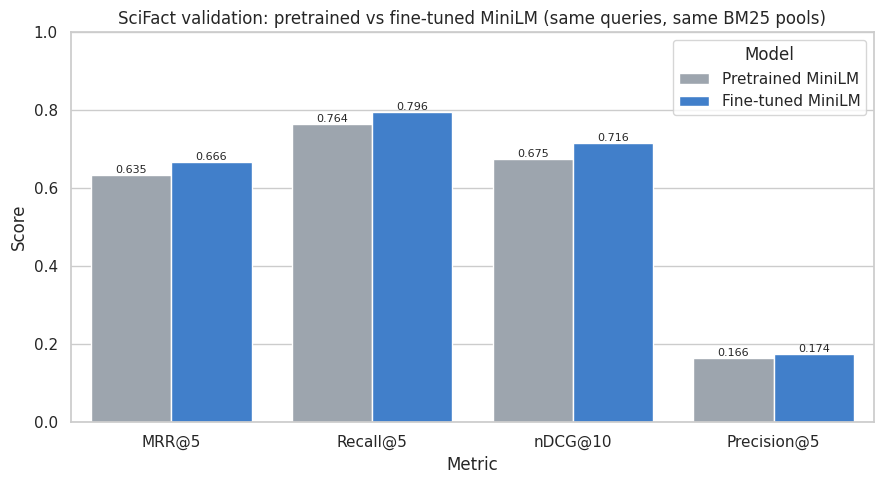

nDCG@10 per query -> improved: 30 | worse: 12 | unchanged: 80


In [42]:
def save_eval_artifacts():
    """Write fine-tuned metrics to results/ and into the model folder (called after each evaluation)."""
    rows = [{"Model": m, "Dataset": d, **metrics} for (m, d), metrics in ALL_RESULTS.items() if m.startswith("Fine-tuned")]
    if rows:
        pd.DataFrame(rows).to_csv(RESULTS_DIR / "finetuned_metrics.csv", index=False)
    serializable = {f"{m} | {d}": metrics for (m, d), metrics in ALL_RESULTS.items()}
    with open(FINETUNED_DIR / "evaluation_results.json", "w") as f:
        json.dump(serializable, f, indent=2)


finetuned_val_rankings = rerank_pools(best_model, tokenizer, val_pools, val_queries, corpus,
                                      CONFIG["rerank_depth"], "Fine-tuned: validation")
finetuned_metrics, finetuned_per_query = compute_ranking_metrics(finetuned_val_rankings, val_qrels)
ALL_RESULTS[("Fine-tuned MiniLM", "SciFact validation")] = finetuned_metrics
save_eval_artifacts()

comparison_df = pd.DataFrame({"Pretrained MiniLM": {m: baseline_metrics[m] for m in METRIC_NAMES},
                              "Fine-tuned MiniLM": {m: finetuned_metrics[m] for m in METRIC_NAMES}})
comparison_df["Absolute change"] = comparison_df["Fine-tuned MiniLM"] - comparison_df["Pretrained MiniLM"]
comparison_df["Relative change (%)"] = np.where(
    comparison_df["Pretrained MiniLM"] > 0,
    100 * comparison_df["Absolute change"] / comparison_df["Pretrained MiniLM"].replace(0, np.nan), np.nan)
print(f"Validation queries evaluated: {finetuned_metrics['num_queries']} (same queries and pools for both models)")
display(comparison_df.round(4))

plot_df = comparison_df[["Pretrained MiniLM", "Fine-tuned MiniLM"]].reset_index().melt(
    id_vars="index", var_name="Model", value_name="Score").rename(columns={"index": "Metric"})
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette=["#9aa5b1", "#2a7de1"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.title("SciFact validation: pretrained vs fine-tuned MiniLM (same queries, same BM25 pools)")
plt.ylim(0, min(1.0, plot_df["Score"].max() * 1.2 + 0.05))
plt.tight_layout()
plt.savefig(PLOTS_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Per-query view: how many validation queries got better / worse / the same nDCG@10?
delta = (finetuned_per_query.set_index("query_id")["nDCG@10"] - baseline_per_query.set_index("query_id")["nDCG@10"])
print(f"nDCG@10 per query -> improved: {(delta > 1e-9).sum()} | worse: {(delta < -1e-9).sum()} | unchanged: {(delta.abs() <= 1e-9).sum()}")

# 16. Final Evaluation on Official SciFact Test Data

All training decisions (epochs, early stopping, checkpoint choice) were made with **validation data only**. Only now do we use the **official SciFact test queries and qrels**, exactly once, for reporting. Nothing below feeds back into training or tuning.

Procedure: BM25 top-100 over the SciFact corpus per test query → rerank with the model → metrics against the test qrels. The pretrained model is evaluated the same way for a fair comparison (this is reporting, not tuning).

In [43]:
test_pools = bm25_retrieve(scifact_bm25, scifact_doc_ids, test_queries, top_k=CONFIG["rerank_depth"])
print(f"Test queries: {len(test_queries)} | pool recall@{CONFIG['rerank_depth']}: "
      f"{pool_recall(test_pools, test_qrels, CONFIG['rerank_depth']):.4f}")

ALL_RESULTS[("BM25 (first stage)", "SciFact test")], _ = compute_ranking_metrics(test_pools, test_qrels)

pretrained_test_rankings = rerank_pools(pretrained_model, tokenizer, test_pools, test_queries, corpus,
                                        CONFIG["rerank_depth"], "Pretrained: test")
ALL_RESULTS[("Pretrained MiniLM", "SciFact test")], _ = compute_ranking_metrics(pretrained_test_rankings, test_qrels)

finetuned_test_rankings = rerank_pools(best_model, tokenizer, test_pools, test_queries, corpus,
                                       CONFIG["rerank_depth"], "Fine-tuned: test")
ALL_RESULTS[("Fine-tuned MiniLM", "SciFact test")], _ = compute_ranking_metrics(finetuned_test_rankings, test_qrels)
save_eval_artifacts()

test_table = pd.DataFrame({
    name: {m: ALL_RESULTS[(name, "SciFact test")][m] for m in METRIC_NAMES}
    for name in ["BM25 (first stage)", "Pretrained MiniLM", "Fine-tuned MiniLM"]
}).T
test_table["Absolute change vs pretrained"] = test_table["nDCG@10"] - test_table.loc["Pretrained MiniLM", "nDCG@10"]
test_table = test_table.rename(columns={"Absolute change vs pretrained": "nDCG@10 change vs pretrained"})
display(test_table.round(4))

BM25 retrieval:   0%|          | 0/300 [00:00<?, ?it/s]

Test queries: 300 | pool recall@100: 0.8859


Pretrained: test:   0%|          | 0/469 [00:00<?, ?it/s]

Fine-tuned: test:   0%|          | 0/469 [00:00<?, ?it/s]

,MRR@5,Recall@5,nDCG@10,Precision@5,nDCG@10 change vs pretrained
BM25 (first stage),0.6302,0.7276,0.6701,0.1580,-0.0061
Pretrained MiniLM,0.6421,0.7352,0.6762,0.1627,0.0000
Fine-tuned MiniLM,0.6863,0.7728,0.7144,0.1713,0.0382


# 17. Independent Evaluation on SCIDOCS

**SCIDOCS** is a scientific benchmark from a different task family: the *query* is the **title of a paper** and the relevant documents are papers it **cites** (or that are related by citation behaviour), rather than abstracts that confirm or refute a *claim*. We do **not** assume SciFact and SCIDOCS share the same relevance definition or task distribution – this evaluation measures how well a SciFact-fine-tuned reranker transfers to a *different* kind of scientific relevance.

Rules:

* SCIDOCS is **never used for training or any choice of hyperparameters/checkpoints**.
* We use BEIR's official `test` split and its qrels. SCIDOCS qrels contain judged-irrelevant (`0`) and relevant (`1`) entries; only score `> 0` counts as relevant.
* The same protocol as before: BM25 top-100 pool, reranked by each model. If the query paper is itself in the corpus, it is removed from its own candidate list.
* The pretrained model is evaluated too, so a drop (or gain) can be attributed to fine-tuning rather than to the dataset being hard.

In [44]:
scidocs_dir = download_beir_dataset("scidocs")
scidocs_corpus, scidocs_queries, scidocs_qrels = GenericDataLoader(data_folder=str(scidocs_dir)).load(split="test")

print(f"SCIDOCS documents: {len(scidocs_corpus):,} | test queries: {len(scidocs_queries):,} | "
      f"judgments: {sum(len(d) for d in scidocs_qrels.values()):,}")
print("Relevance score values in SCIDOCS qrels:", Counter(s for d in scidocs_qrels.values() for s in d.values()))

example_sd_qid = next(iter(scidocs_queries))
print("\nExample SCIDOCS query (a paper title):", scidocs_queries[example_sd_qid])
example_sd_did = next(d for d, s in scidocs_qrels[example_sd_qid].items() if s > 0 and d in scidocs_corpus)
print("Example relevant document:", passage_text(scidocs_corpus[example_sd_did])[:250], "...")

scidocs_bm25, scidocs_doc_ids = build_bm25_index(scidocs_corpus)
scidocs_pools = bm25_retrieve(scidocs_bm25, scidocs_doc_ids, scidocs_queries, top_k=CONFIG["rerank_depth"],
                              drop_self_match=True)
print(f"\nSCIDOCS pool recall@{CONFIG['rerank_depth']}: {pool_recall(scidocs_pools, scidocs_qrels, CONFIG['rerank_depth']):.4f}")

ALL_RESULTS[("BM25 (first stage)", "SCIDOCS test")], _ = compute_ranking_metrics(scidocs_pools, scidocs_qrels)

pretrained_sd_rankings = rerank_pools(pretrained_model, tokenizer, scidocs_pools, scidocs_queries, scidocs_corpus,
                                      CONFIG["rerank_depth"], "Pretrained: SCIDOCS")
ALL_RESULTS[("Pretrained MiniLM", "SCIDOCS test")], _ = compute_ranking_metrics(pretrained_sd_rankings, scidocs_qrels)

finetuned_sd_rankings = rerank_pools(best_model, tokenizer, scidocs_pools, scidocs_queries, scidocs_corpus,
                                     CONFIG["rerank_depth"], "Fine-tuned: SCIDOCS")
ALL_RESULTS[("Fine-tuned MiniLM", "SCIDOCS test")], _ = compute_ranking_metrics(finetuned_sd_rankings, scidocs_qrels)
save_eval_artifacts()

sd_table = pd.DataFrame({
    name: {m: ALL_RESULTS[(name, "SCIDOCS test")][m] for m in METRIC_NAMES}
    for name in ["BM25 (first stage)", "Pretrained MiniLM", "Fine-tuned MiniLM"]
}).T
display(sd_table.round(4))

scidocs: found existing copy at /kaggle/working/beir_raw_data/scidocs


  0%|          | 0/25657 [00:00<?, ?it/s]

SCIDOCS documents: 25,657 | test queries: 1,000 | judgments: 29,928
Relevance score values in SCIDOCS qrels: Counter({0: 25000, 1: 4928})

Example SCIDOCS query (a paper title): A Direct Search Method to solve Economic Dispatch Problem with Valve-Point Effect
Example relevant document: A hybrid of genetic algorithm and particle swarm optimization for recurrent network design. An evolutionary recurrent network which automates the design of recurrent neural/fuzzy networks using a new evolutionary learning algorithm is proposed in thi ...


Tokenizing corpus:   0%|          | 0/25657 [00:00<?, ?it/s]

BM25 retrieval:   0%|          | 0/1000 [00:00<?, ?it/s]


SCIDOCS pool recall@100: 0.3549


Pretrained: SCIDOCS:   0%|          | 0/1563 [00:00<?, ?it/s]

Fine-tuned: SCIDOCS:   0%|          | 0/1563 [00:00<?, ?it/s]

,MRR@5,Recall@5,nDCG@10,Precision@5
BM25 (first stage),0.2608,0.1117,0.1540,0.1104
Pretrained MiniLM,0.2795,0.1212,0.1634,0.1196
Fine-tuned MiniLM,0.2498,0.1070,0.1457,0.1056


### Reading the SCIDOCS result

Compare the *Fine-tuned* row with the *Pretrained* row above, not with SciFact numbers: the two datasets have different query types, relevance definitions and difficulty, so absolute scores are not comparable across datasets. A lower score for the fine-tuned model than for the pretrained one would suggest the model specialized to SciFact-style claim/abstract relevance at the cost of broader, MS MARCO-style relevance; an equal or higher score would suggest the adaptation did not hurt transfer. The programmatic summary in Section 18 states which case was actually measured.

# 17B. Statistical Evidence, Ablation and Robustness

Averages alone cannot tell us whether an improvement is real or just luck in *which* queries were sampled. This section adds the evidence a careful reviewer would ask for. **It only analyses models and rankings that already exist; none of it is used to choose checkpoints or hyperparameters.**

1. **Paired bootstrap confidence intervals.** Every query is scored by both models, so we look at the *per-query difference* (fine-tuned − pretrained). Resampling queries with replacement 10,000 times gives a 95% interval for the mean difference. If the interval excludes 0, the change is unlikely to be sampling noise.
2. **Wilcoxon signed-rank test** on the same per-query differences (a non-parametric significance test) and a **sign test** on wins vs losses.
3. **Per-query win / loss / tie analysis** – on how many queries did fine-tuning help or hurt?
4. **Negative-sampling ablation.** We retrain the identical recipe with *random* negatives instead of BM25 hard negatives (same number of negatives, same seed, same split). Comparing the two answers the question the earlier sections could not: *did hard-negative mining help?*
5. **Weight-interpolation trade-off curve.** We blend the pretrained and fine-tuned weights, `w = (1-α)·w_pretrained + α·w_finetuned`, and measure all three evaluation sets. This is a **diagnostic** of the SciFact-vs-SCIDOCS trade-off. α is *not* chosen using test or SCIDOCS results.

Two switches below let you skip the retraining ablation or the interpolation sweep if you are short on GPU time.

,Dataset,Metric,Pretrained,Fine-tuned,Delta,CI_low,CI_high,Wilcoxon_p,Verdict (95% CI),Queries
0,SciFact validation,MRR@5,0.6350,0.6663,0.0313,-0.0134,0.0770,0.2517,not significant,122
1,SciFact validation,Recall@5,0.7637,0.7964,0.0328,-0.0205,0.0902,0.3071,not significant,122
2,SciFact validation,nDCG@10,0.6746,0.7162,0.0417,0.0047,0.0784,0.0425,better,122
3,SciFact validation,Precision@5,0.1656,0.1738,0.0082,-0.0033,0.0197,0.2668,not significant,122
4,SciFact test,MRR@5,0.6421,0.6863,0.0442,0.0141,0.0752,0.0046,better,300
5,SciFact test,Recall@5,0.7352,0.7728,0.0377,0.0041,0.0738,0.0307,better,300
6,SciFact test,nDCG@10,0.6762,0.7144,0.0382,0.0135,0.0642,0.0054,better,300
7,SciFact test,Precision@5,0.1627,0.1713,0.0087,0.0000,0.0173,0.0782,not significant,300
8,SCIDOCS test,MRR@5,0.2795,0.2498,-0.0297,-0.0422,-0.0173,0.0000,worse,1000
9,SCIDOCS test,Recall@5,0.1212,0.1070,-0.0142,-0.0198,-0.0088,0.0000,worse,1000



HEADLINE (nDCG@10, fine-tuned minus pretrained, 95% paired-bootstrap CI):
  SciFact validation   +0.0417  [+0.0047, +0.0784]  n=122  -> better
  SciFact test         +0.0382  [+0.0135, +0.0642]  n=300  -> better
  SCIDOCS test         -0.0177  [-0.0230, -0.0124]  n=1000  -> worse


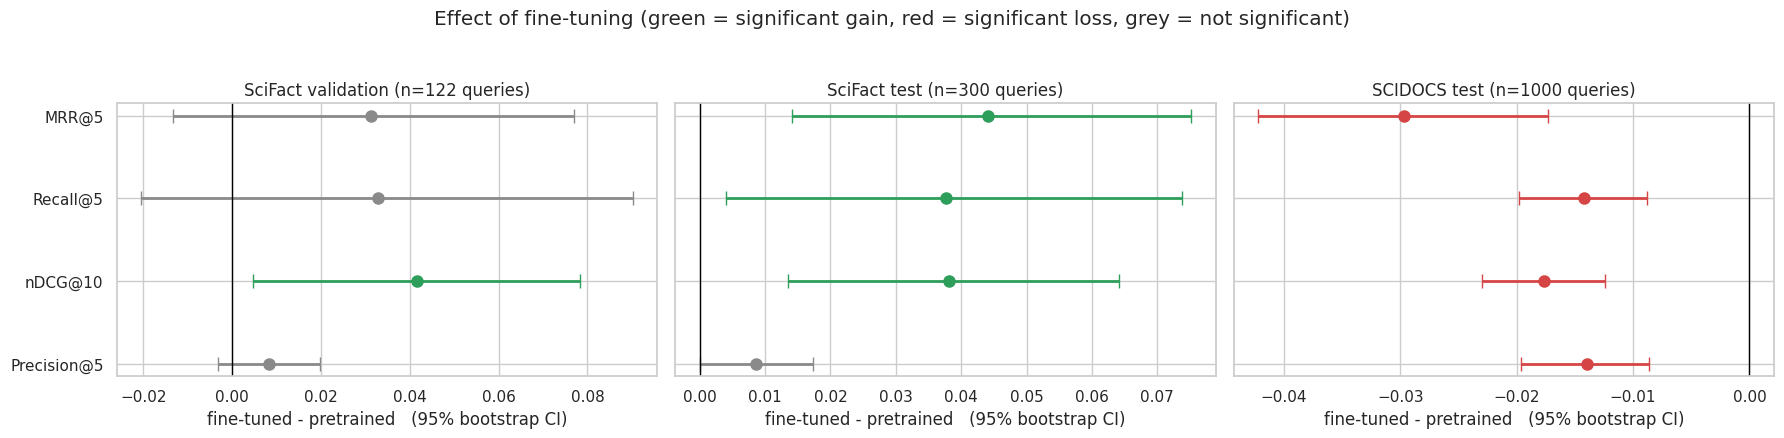

In [45]:
from scipy import stats

N_BOOTSTRAP = 10000
boot_rng = np.random.default_rng(SEED)


def paired_bootstrap_ci(differences: np.ndarray, n_resamples: int = N_BOOTSTRAP):
    """95% bootstrap CI for the mean of per-query differences (queries are resampled with replacement)."""
    n = len(differences)
    resample_idx = boot_rng.integers(0, n, size=(n_resamples, n))
    boot_means = differences[resample_idx].mean(axis=1)
    return float(np.percentile(boot_means, 2.5)), float(np.percentile(boot_means, 97.5))


eval_sets = {
    "SciFact validation": (pretrained_val_rankings, finetuned_val_rankings, val_qrels),
    "SciFact test": (pretrained_test_rankings, finetuned_test_rankings, test_qrels),
    "SCIDOCS test": (pretrained_sd_rankings, finetuned_sd_rankings, scidocs_qrels),
}

stat_rows, per_query_tables = [], {}
for dataset_name, (pre_rankings, ft_rankings, qrels_for_set) in eval_sets.items():
    _, pre_pq = compute_ranking_metrics(pre_rankings, qrels_for_set)
    _, ft_pq = compute_ranking_metrics(ft_rankings, qrels_for_set)
    merged = pre_pq.merge(ft_pq, on="query_id", suffixes=("_pre", "_ft"))     # same queries for both models
    per_query_tables[dataset_name] = merged
    for metric in METRIC_NAMES:
        diffs = (merged[f"{metric}_ft"] - merged[f"{metric}_pre"]).to_numpy()
        ci_low, ci_high = paired_bootstrap_ci(diffs)
        nonzero = diffs[diffs != 0]
        try:
            wilcoxon_p = float(stats.wilcoxon(nonzero).pvalue) if len(nonzero) > 0 else float("nan")
        except ValueError:
            wilcoxon_p = float("nan")
        verdict = "better" if ci_low > 0 else ("worse" if ci_high < 0 else "not significant")
        stat_rows.append({"Dataset": dataset_name, "Metric": metric,
                          "Pretrained": merged[f"{metric}_pre"].mean(), "Fine-tuned": merged[f"{metric}_ft"].mean(),
                          "Delta": diffs.mean(), "CI_low": ci_low, "CI_high": ci_high,
                          "Wilcoxon_p": wilcoxon_p, "Verdict (95% CI)": verdict, "Queries": len(merged)})

stat_df = pd.DataFrame(stat_rows)
stat_df.to_csv(RESULTS_DIR / "statistical_significance.csv", index=False)
display(stat_df.round(4))

print("\nHEADLINE (nDCG@10, fine-tuned minus pretrained, 95% paired-bootstrap CI):")
for _, row in stat_df[stat_df["Metric"] == "nDCG@10"].iterrows():
    print(f"  {row['Dataset']:20s} {row['Delta']:+.4f}  [{row['CI_low']:+.4f}, {row['CI_high']:+.4f}]  "
          f"n={row['Queries']}  -> {row['Verdict (95% CI)']}")

# ---------- Forest plot: every metric, every dataset ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, dataset_name in zip(axes, eval_sets):
    subset = stat_df[stat_df["Dataset"] == dataset_name].reset_index(drop=True)
    for i, row in subset.iterrows():
        color = "#2e9e5b" if row["CI_low"] > 0 else ("#d64545" if row["CI_high"] < 0 else "#8a8a8a")
        ax.errorbar(row["Delta"], i, xerr=[[row["Delta"] - row["CI_low"]], [row["CI_high"] - row["Delta"]]],
                    fmt="o", color=color, ecolor=color, capsize=5, lw=2, markersize=8)
    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(range(len(subset)))
    ax.set_yticklabels(subset["Metric"])
    ax.invert_yaxis()
    ax.set_title(f"{dataset_name} (n={subset['Queries'].iloc[0]} queries)")
    ax.set_xlabel("fine-tuned - pretrained   (95% bootstrap CI)")
fig.suptitle("Effect of fine-tuning (green = significant gain, red = significant loss, grey = not significant)", y=1.04)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "improvement_with_ci.png", dpi=150, bbox_inches="tight")
plt.show()

,Dataset,Improved,Worse,Tied,Improved %,Worse %,Tied %,Sign-test p
0,SciFact validation,30,12,80,24.5902,9.8361,65.5738,0.0079
1,SciFact test,53,35,212,17.6667,11.6667,70.6667,0.0693
2,SCIDOCS test,148,284,568,14.8000,28.4000,56.8000,0.0000


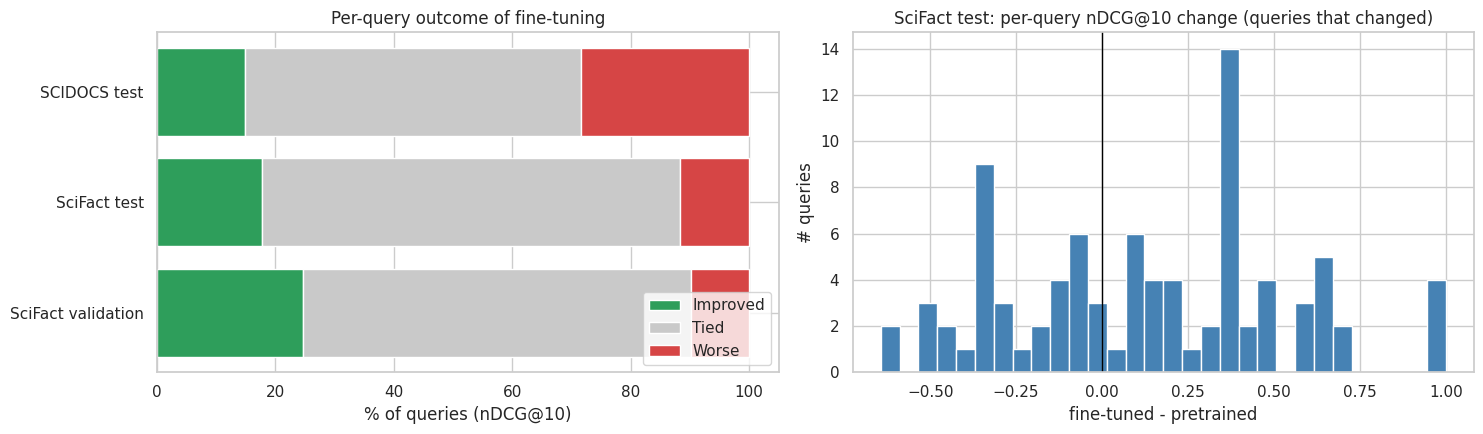

In [46]:
# ---------- Per-query win / loss / tie analysis on nDCG@10 ----------
win_rows = []
for dataset_name, merged in per_query_tables.items():
    d = (merged["nDCG@10_ft"] - merged["nDCG@10_pre"]).to_numpy()
    wins, losses = int((d > 1e-9).sum()), int((d < -1e-9).sum())
    ties = len(d) - wins - losses
    sign_p = float(stats.binomtest(wins, wins + losses, 0.5).pvalue) if wins + losses > 0 else float("nan")
    win_rows.append({"Dataset": dataset_name, "Improved": wins, "Worse": losses, "Tied": ties,
                     "Improved %": 100 * wins / len(d), "Worse %": 100 * losses / len(d), "Tied %": 100 * ties / len(d),
                     "Sign-test p": sign_p})
win_df = pd.DataFrame(win_rows)
win_df.to_csv(RESULTS_DIR / "per_query_win_loss.csv", index=False)
display(win_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
left = np.zeros(len(win_df))
for column, color in [("Improved %", "#2e9e5b"), ("Tied %", "#c9c9c9"), ("Worse %", "#d64545")]:
    axes[0].barh(win_df["Dataset"], win_df[column], left=left, color=color, label=column.replace(" %", ""))
    left += win_df[column].to_numpy()
axes[0].set_xlabel("% of queries (nDCG@10)")
axes[0].set_title("Per-query outcome of fine-tuning")
axes[0].legend(loc="lower right")

test_deltas = (per_query_tables["SciFact test"]["nDCG@10_ft"] - per_query_tables["SciFact test"]["nDCG@10_pre"])
axes[1].hist(test_deltas[test_deltas.abs() > 1e-9], bins=30, color="steelblue")
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("SciFact test: per-query nDCG@10 change (queries that changed)")
axes[1].set_xlabel("fine-tuned - pretrained")
axes[1].set_ylabel("# queries")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "per_query_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

Ablation pairs -> train: 3,136 | validation: 540 (random negatives)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Validation loss BEFORE fine-tuning (pretrained weights): 0.3884


Epoch 1:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.1757 | val loss 0.0767 | lr 1.48e-05 | 20.2s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

Random-neg: SciFact test:   0%|          | 0/469 [00:00<?, ?it/s]

Random-neg: SCIDOCS test:   0%|          | 0/1563 [00:00<?, ?it/s]

,Dataset,Model,MRR@5,Recall@5,nDCG@10,Precision@5
0,SciFact validation,Pretrained MiniLM,0.6350,0.7637,0.6746,0.1656
1,SciFact validation,Ablation: random negatives,0.6833,0.7862,0.7227,0.1721
2,SciFact validation,Fine-tuned (BM25 hard negatives),0.6663,0.7964,0.7162,0.1738
3,SciFact test,Pretrained MiniLM,0.6421,0.7352,0.6762,0.1627
4,SciFact test,Ablation: random negatives,0.7044,0.8026,0.7360,0.1773
5,SciFact test,Fine-tuned (BM25 hard negatives),0.6863,0.7728,0.7144,0.1713
6,SCIDOCS test,Pretrained MiniLM,0.2795,0.1212,0.1634,0.1196
7,SCIDOCS test,Ablation: random negatives,0.2762,0.1196,0.1621,0.1180
8,SCIDOCS test,Fine-tuned (BM25 hard negatives),0.2498,0.1070,0.1457,0.1056



Hard-negative run minus random-negative run (nDCG@10, 95% paired-bootstrap CI):
  SciFact validation   -0.0064  [-0.0358, +0.0227]  -> no significant difference
  SciFact test         -0.0217  [-0.0435, -0.0006]  -> random negatives better
  SCIDOCS test         -0.0164  [-0.0212, -0.0114]  -> random negatives better


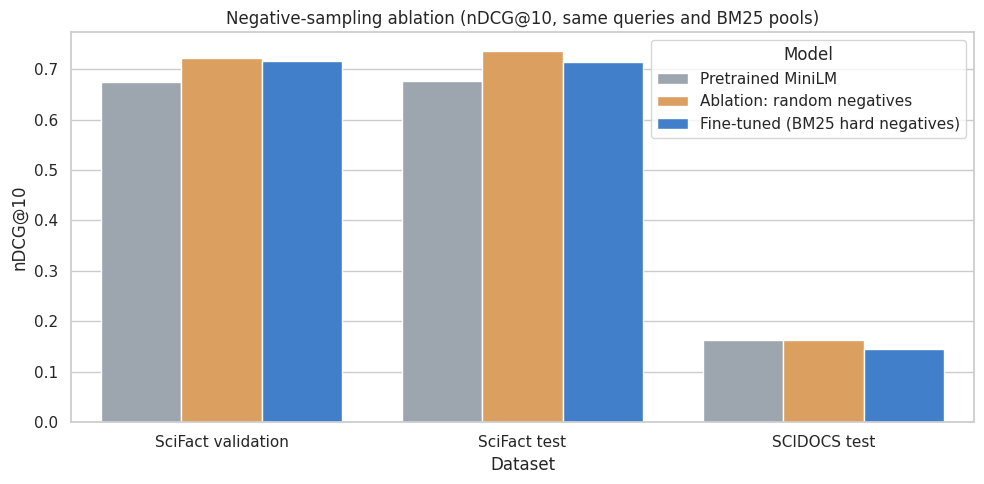

In [47]:
# ---------- Ablation: random negatives vs BM25 hard negatives (identical recipe, seed and split) ----------
RUN_NEGATIVE_ABLATION = True      # set to False to skip the retraining (takes about as long as the main training)

if RUN_NEGATIVE_ABLATION:
    set_seed(SEED)
    ablation_rng = np.random.default_rng(SEED)
    all_corpus_ids = list(corpus.keys())

    # Same number of negatives per query as the hard-negative run; documents judged for that query are excluded.
    random_negative_rows = []
    for qid, group in hard_negative_df.groupby("query_id"):
        judged = set(train_qrels_all[qid].keys())
        chosen = set()
        while len(chosen) < len(group):
            candidate = all_corpus_ids[int(ablation_rng.integers(0, len(all_corpus_ids)))]
            if candidate in judged or candidate in chosen:
                continue
            chosen.add(candidate)
        for did in sorted(chosen):
            random_negative_rows.append({"query_id": qid, "document_id": did, "query": train_queries_all[qid],
                                         "passage": passage_text(corpus[did]), "label": 0,
                                         "source": "random_negative", "bm25_rank": -1})
    random_negative_df = pd.DataFrame(random_negative_rows)
    ablation_pairs = pd.concat([positive_df, random_negative_df], ignore_index=True)
    abl_train_df = ablation_pairs[ablation_pairs["query_id"].isin(train_qid_set)].sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    abl_val_df = ablation_pairs[ablation_pairs["query_id"].isin(val_qid_set)].reset_index(drop=True)
    assert set(abl_train_df["query_id"]).isdisjoint(set(abl_val_df["query_id"]))
    print(f"Ablation pairs -> train: {len(abl_train_df):,} | validation: {len(abl_val_df):,} (random negatives)")

    abl_train_loader = DataLoader(QueryPassageDataset(abl_train_df, tokenizer, CONFIG["max_length"]),
                                  batch_size=CONFIG["batch_size"], shuffle=True,
                                  generator=torch.Generator().manual_seed(SEED), collate_fn=collate_fn,
                                  num_workers=2, pin_memory=USE_AMP)
    abl_val_loader = DataLoader(QueryPassageDataset(abl_val_df, tokenizer, CONFIG["max_length"]),
                                batch_size=CONFIG["batch_size"], shuffle=False, collate_fn=collate_fn,
                                num_workers=2, pin_memory=USE_AMP)

    abl_model = AutoModelForSequenceClassification.from_pretrained(PRETRAINED_DIR).to(DEVICE)
    abl_param_groups = [
        {"params": [p for n, p in abl_model.named_parameters() if not any(k in n for k in no_decay_keywords)],
         "weight_decay": CONFIG["weight_decay"]},
        {"params": [p for n, p in abl_model.named_parameters() if any(k in n for k in no_decay_keywords)],
         "weight_decay": 0.0},
    ]
    abl_optimizer = torch.optim.AdamW(abl_param_groups, lr=CONFIG["learning_rate"])
    abl_total_steps = math.ceil(len(abl_train_loader) / CONFIG["gradient_accumulation_steps"]) * CONFIG["epochs"]
    abl_scheduler = get_linear_schedule_with_warmup(abl_optimizer, int(CONFIG["warmup_ratio"] * abl_total_steps), abl_total_steps)
    abl_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    ABLATION_DIR = ROOT / "ablation-random-negatives"
    ABLATION_DIR.mkdir(parents=True, exist_ok=True)
    abl_history, _, abl_best_epoch, abl_best_val_loss, _ = fit(
        abl_model, abl_train_loader, abl_val_loader, abl_optimizer, abl_scheduler, abl_scaler, loss_fn,
        CONFIG, DEVICE, USE_AMP, ABLATION_DIR)
    abl_history.to_csv(RESULTS_DIR / "ablation_random_negatives_history.csv", index=False)

    abl_best = AutoModelForSequenceClassification.from_pretrained(ABLATION_DIR).to(DEVICE).eval()
    ABL_NAME = "Ablation: random negatives"
    ablation_rankings = {}
    for dataset_name, (pools_, queries_, corpus_, qrels_) in {
        "SciFact validation": (val_pools, val_queries, corpus, val_qrels),
        "SciFact test": (test_pools, test_queries, corpus, test_qrels),
        "SCIDOCS test": (scidocs_pools, scidocs_queries, scidocs_corpus, scidocs_qrels),
    }.items():
        ablation_rankings[dataset_name] = rerank_pools(abl_best, tokenizer, pools_, queries_, corpus_,
                                                       CONFIG["rerank_depth"], f"Random-neg: {dataset_name}")
        ALL_RESULTS[(ABL_NAME, dataset_name)], _ = compute_ranking_metrics(ablation_rankings[dataset_name], qrels_)

    # ---------- Compare the three models ----------
    rows = []
    for dataset_name in eval_sets:
        for model_name in ["Pretrained MiniLM", ABL_NAME, "Fine-tuned MiniLM"]:
            metrics = ALL_RESULTS[(model_name, dataset_name)]
            rows.append({"Dataset": dataset_name, "Model": model_name.replace("Fine-tuned MiniLM", "Fine-tuned (BM25 hard negatives)"),
                         **{m: metrics[m] for m in METRIC_NAMES}})
    ablation_df = pd.DataFrame(rows)
    ablation_df.to_csv(RESULTS_DIR / "negative_ablation.csv", index=False)
    display(ablation_df.round(4))

    # Paired bootstrap: hard negatives minus random negatives
    print("\nHard-negative run minus random-negative run (nDCG@10, 95% paired-bootstrap CI):")
    for dataset_name, (_, ft_rankings, qrels_for_set) in eval_sets.items():
        _, hard_pq = compute_ranking_metrics(ft_rankings, qrels_for_set)
        _, rand_pq = compute_ranking_metrics(ablation_rankings[dataset_name], qrels_for_set)
        both = hard_pq.merge(rand_pq, on="query_id", suffixes=("_hard", "_rand"))
        diffs = (both["nDCG@10_hard"] - both["nDCG@10_rand"]).to_numpy()
        lo, hi = paired_bootstrap_ci(diffs)
        verdict = "hard negatives better" if lo > 0 else ("random negatives better" if hi < 0 else "no significant difference")
        print(f"  {dataset_name:20s} {diffs.mean():+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

    plt.figure(figsize=(10, 5))
    sns.barplot(data=ablation_df, x="Dataset", y="nDCG@10", hue="Model", palette=["#9aa5b1", "#f0a04b", "#2a7de1"])
    plt.title("Negative-sampling ablation (nDCG@10, same queries and BM25 pools)")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "negative_ablation.png", dpi=150, bbox_inches="tight")
    plt.show()

    del abl_model, abl_best, abl_optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("Negative ablation skipped (RUN_NEGATIVE_ABLATION = False).")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

alpha=0.25: SciFact validation:   0%|          | 0/191 [00:00<?, ?it/s]

alpha=0.25: SciFact test:   0%|          | 0/469 [00:00<?, ?it/s]

alpha=0.25: SCIDOCS test:   0%|          | 0/1563 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

alpha=0.5: SciFact validation:   0%|          | 0/191 [00:00<?, ?it/s]

... (3 outputs left out)

alpha=0.75: SciFact validation:   0%|          | 0/191 [00:00<?, ?it/s]

alpha=0.75: SciFact test:   0%|          | 0/469 [00:00<?, ?it/s]

alpha=0.75: SCIDOCS test:   0%|          | 0/1563 [00:00<?, ?it/s]

Dataset,SCIDOCS test,SciFact test,SciFact validation
alpha,,,
0.00,0.1634,0.6762,0.6746
0.25,0.1641,0.7002,0.7040
0.50,0.1616,0.7131,0.7209
0.75,0.1563,0.7242,0.7292
1.00,0.1457,0.7144,0.7162


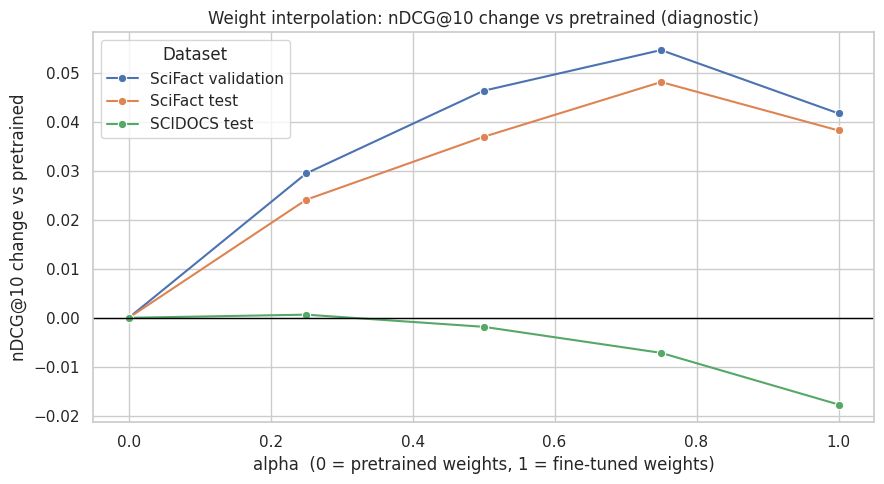

In [48]:
# ---------- Weight interpolation: SciFact-vs-SCIDOCS trade-off (DIAGNOSTIC; alpha is NOT tuned on test/SCIDOCS) ----------
RUN_WEIGHT_INTERPOLATION = True
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]       # 0 = pretrained, 1 = fine-tuned

if RUN_WEIGHT_INTERPOLATION:
    pretrained_state = {k: v.detach().cpu() for k, v in pretrained_model.state_dict().items()}
    finetuned_state = {k: v.detach().cpu() for k, v in best_model.state_dict().items()}

    def build_interpolated_model(alpha: float):
        """w = (1 - alpha) * w_pretrained + alpha * w_finetuned for every floating-point parameter."""
        blended = {k: (pretrained_state[k] + alpha * (finetuned_state[k] - pretrained_state[k]))
                   if finetuned_state[k].is_floating_point() else finetuned_state[k] for k in finetuned_state}
        model_alpha = AutoModelForSequenceClassification.from_pretrained(FINETUNED_DIR)
        model_alpha.load_state_dict(blended)
        return model_alpha.to(DEVICE).eval()

    interp_sets = {
        "SciFact validation": (val_pools, val_queries, corpus, val_qrels),
        "SciFact test": (test_pools, test_queries, corpus, test_qrels),
        "SCIDOCS test": (scidocs_pools, scidocs_queries, scidocs_corpus, scidocs_qrels),
    }
    interp_rows = []
    for alpha in ALPHAS:
        if alpha in (0.0, 1.0):                                  # endpoints were already measured
            name = "Pretrained MiniLM" if alpha == 0.0 else "Fine-tuned MiniLM"
            for dataset_name in interp_sets:
                interp_rows.append({"alpha": alpha, "Dataset": dataset_name, "nDCG@10": ALL_RESULTS[(name, dataset_name)]["nDCG@10"]})
            continue
        model_alpha = build_interpolated_model(alpha)
        for dataset_name, (pools_, queries_, corpus_, qrels_) in interp_sets.items():
            rankings_ = rerank_pools(model_alpha, tokenizer, pools_, queries_, corpus_, CONFIG["rerank_depth"],
                                     f"alpha={alpha}: {dataset_name}")
            metrics_, _ = compute_ranking_metrics(rankings_, qrels_)
            interp_rows.append({"alpha": alpha, "Dataset": dataset_name, "nDCG@10": metrics_["nDCG@10"]})
        del model_alpha
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    interp_df = pd.DataFrame(interp_rows)
    interp_df["nDCG@10 change vs pretrained"] = interp_df["nDCG@10"] - interp_df.groupby("Dataset")["nDCG@10"].transform("first")
    interp_df.to_csv(RESULTS_DIR / "weight_interpolation.csv", index=False)
    display(interp_df.pivot(index="alpha", columns="Dataset", values="nDCG@10").round(4))

    plt.figure(figsize=(9, 5))
    sns.lineplot(data=interp_df, x="alpha", y="nDCG@10 change vs pretrained", hue="Dataset", marker="o")
    plt.axhline(0, color="black", lw=1)
    plt.xlabel("alpha  (0 = pretrained weights, 1 = fine-tuned weights)")
    plt.title("Weight interpolation: nDCG@10 change vs pretrained (diagnostic)")
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "interpolation_tradeoff.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Weight interpolation skipped (RUN_WEIGHT_INTERPOLATION = False).")

### How to read Section 17B

* **Forest plot / table:** a green interval (entirely above 0) means the improvement survives resampling of queries; grey means the data cannot distinguish the change from noise; red means a reliable loss. The forest plot is the honest summary of the whole project in one picture.
* **Win / loss / tie:** shows whether the average gain comes from many small improvements or a few large ones.
* **Ablation:** the confidence interval on *hard − random* is the evidence for or against hard-negative mining. A "no significant difference" result is still a legitimate finding (with this little training data, random and BM25 negatives may behave similarly).
* **Interpolation curve:** the shape shows how much of the SciFact gain can be kept while limiting the SCIDOCS loss. If you wanted to *deploy* a blended model, α would have to be chosen on SciFact **validation** data (or on a separate, general-purpose validation set), never on test or SCIDOCS.

# 18. Final Results and Research Discussion

The table below collects every measured result. Rows for **BM25** are included as a first-stage reference (they show the ordering the reranker started from). SciFact is reported on both the **validation split** (held-out train queries, used for model selection) and the **official test split** (untouched until Section 16).

The discussion cell after the table is **generated from the measured numbers**, so it can never claim an improvement that did not happen.

,Model,Dataset,MRR@5,Recall@5,nDCG@10,Precision@5,Queries
0,BM25 (first stage),SciFact validation,0.6064,0.6633,0.6513,0.1426,122
1,Pretrained MiniLM,SciFact validation,0.6350,0.7637,0.6746,0.1656,122
2,Fine-tuned MiniLM,SciFact validation,0.6663,0.7964,0.7162,0.1738,122
3,BM25 (first stage),SciFact test,0.6302,0.7276,0.6701,0.1580,300
4,Pretrained MiniLM,SciFact test,0.6421,0.7352,0.6762,0.1627,300
5,Fine-tuned MiniLM,SciFact test,0.6863,0.7728,0.7144,0.1713,300
6,BM25 (first stage),SCIDOCS test,0.2608,0.1117,0.1540,0.1104,1000
7,Pretrained MiniLM,SCIDOCS test,0.2795,0.1212,0.1634,0.1196,1000
8,Fine-tuned MiniLM,SCIDOCS test,0.2498,0.1070,0.1457,0.1056,1000
9,Ablation: random negatives,SciFact validation,0.6833,0.7862,0.7227,0.1721,122


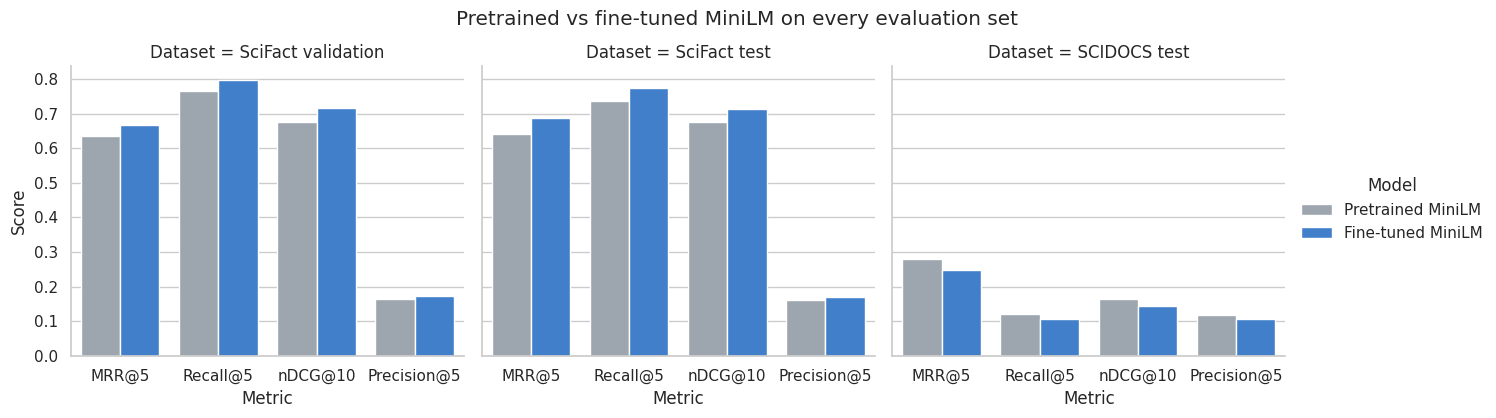

In [49]:
final_rows = []
row_order = [
    ("BM25 (first stage)", "SciFact validation"), ("Pretrained MiniLM", "SciFact validation"), ("Fine-tuned MiniLM", "SciFact validation"),
    ("BM25 (first stage)", "SciFact test"), ("Pretrained MiniLM", "SciFact test"), ("Fine-tuned MiniLM", "SciFact test"),
    ("BM25 (first stage)", "SCIDOCS test"), ("Pretrained MiniLM", "SCIDOCS test"), ("Fine-tuned MiniLM", "SCIDOCS test"),
]
for model_name, dataset_name in row_order:
    metrics = ALL_RESULTS[(model_name, dataset_name)]
    final_rows.append({"Model": model_name, "Dataset": dataset_name, **{m: metrics[m] for m in METRIC_NAMES},
                       "Queries": metrics["num_queries"]})

# Ablation rows (random negatives), if Section 17B's ablation was run
for dataset_name in ["SciFact validation", "SciFact test", "SCIDOCS test"]:
    if ("Ablation: random negatives", dataset_name) in ALL_RESULTS:
        metrics = ALL_RESULTS[("Ablation: random negatives", dataset_name)]
        final_rows.append({"Model": "Ablation: random negatives", "Dataset": dataset_name,
                           **{m: metrics[m] for m in METRIC_NAMES}, "Queries": metrics["num_queries"]})

final_df = pd.DataFrame(final_rows)
final_df.to_csv(RESULTS_DIR / "final_comparison.csv", index=False)
display(final_df.round(4))

# Grouped bar chart of the final table (pretrained vs fine-tuned on every evaluation set)
long_df = final_df[final_df["Model"].isin(["Pretrained MiniLM", "Fine-tuned MiniLM"])].melt(
    id_vars=["Model", "Dataset", "Queries"], value_vars=METRIC_NAMES, var_name="Metric", value_name="Score")
grid = sns.catplot(data=long_df, x="Metric", y="Score", hue="Model", col="Dataset", kind="bar",
                   palette=["#9aa5b1", "#2a7de1"], height=4, aspect=1.1)
grid.fig.suptitle("Pretrained vs fine-tuned MiniLM on every evaluation set", y=1.04)
grid.savefig(PLOTS_DIR / "final_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
def describe_change(dataset_name: str) -> None:
    """Print a factual comparison (pretrained vs fine-tuned) generated from the measured metrics."""
    pre = ALL_RESULTS[("Pretrained MiniLM", dataset_name)]
    fin = ALL_RESULTS[("Fine-tuned MiniLM", dataset_name)]
    print(f"\n[{dataset_name}]")
    for m in METRIC_NAMES:
        diff = fin[m] - pre[m]
        rel = f"{100 * diff / pre[m]:+.1f}%" if pre[m] > 0 else "n/a"
        word = "improved" if diff > 1e-4 else ("decreased" if diff < -1e-4 else "was essentially unchanged")
        print(f"  {m:12s}: {pre[m]:.4f} -> {fin[m]:.4f} ({diff:+.4f}, {rel})  => {word}")


print("=" * 78)
print("AUTO-GENERATED SUMMARY OF MEASURED RESULTS")
print("=" * 78)
for dataset in ["SciFact validation", "SciFact test", "SCIDOCS test"]:
    describe_change(dataset)

# 1) Did fine-tuning improve ranking?
val_gain = ALL_RESULTS[("Fine-tuned MiniLM", "SciFact validation")]["nDCG@10"] - ALL_RESULTS[("Pretrained MiniLM", "SciFact validation")]["nDCG@10"]
test_gain = ALL_RESULTS[("Fine-tuned MiniLM", "SciFact test")]["nDCG@10"] - ALL_RESULTS[("Pretrained MiniLM", "SciFact test")]["nDCG@10"]
print("\n1) Did fine-tuning improve ranking on SciFact?")
print(f"   nDCG@10 change: validation {val_gain:+.4f}, official test {test_gain:+.4f}.")
if val_gain > 1e-4 and test_gain > 1e-4:
    print("   Improvement on both validation and the untouched test split.")
elif val_gain > 1e-4 and test_gain <= 1e-4:
    print("   Improvement on validation but NOT on the test split: the gain did not carry over (small validation set / selection effects).")
elif val_gain <= 1e-4 and test_gain > 1e-4:
    print("   No clear validation gain but an improvement on test; with few queries this difference may be noise.")
else:
    print("   No measurable nDCG@10 improvement on SciFact in this run.")

# 2) Overfitting
print("\n2) Overfitting check (loss curves):")
print(history_df[["epoch", "train_loss", "val_loss"]].round(4).to_string(index=False))
print(f"   Best epoch by validation loss: {best_epoch} of {len(history_df)} run.")
if len(history_df) > best_epoch:
    print("   Validation loss got worse after the best epoch -> overfitting began; the best checkpoint was kept.")
else:
    print("   The best epoch was the last one run -> no overfitting detected by validation loss.")
print("   Note that validation loss is a classification loss; it need not move together with ranking metrics.")

# 3) Hard negatives
print("\n3) Did hard negatives help?")
if ("Ablation: random negatives", "SciFact test") in ALL_RESULTS:
    for dataset in ["SciFact validation", "SciFact test", "SCIDOCS test"]:
        hard = ALL_RESULTS[("Fine-tuned MiniLM", dataset)]["nDCG@10"]
        rand = ALL_RESULTS[("Ablation: random negatives", dataset)]["nDCG@10"]
        pre = ALL_RESULTS[("Pretrained MiniLM", dataset)]["nDCG@10"]
        print(f"   {dataset:20s} nDCG@10: pretrained {pre:.4f} | random negatives {rand:.4f} | BM25 hard negatives {hard:.4f}"
              f" (hard - random = {hard - rand:+.4f})")
    print("   See the paired-bootstrap interval in Section 17B to judge whether the hard-vs-random difference is reliable.")
else:
    print("   The negative ablation was not run, so no gain or loss can be attributed to hard-negative mining.")

# Statistical reliability of the SciFact gain (from Section 17B, if it was run)
if "stat_df" in globals():
    print("\n   Statistical reliability of fine-tuned vs pretrained (nDCG@10, 95% paired-bootstrap CI):")
    for _, row in stat_df[stat_df["Metric"] == "nDCG@10"].iterrows():
        print(f"   {row['Dataset']:20s} {row['Delta']:+.4f} [{row['CI_low']:+.4f}, {row['CI_high']:+.4f}] -> {row['Verdict (95% CI)']}")

# 4) Generalization to SCIDOCS
sd_gain = ALL_RESULTS[("Fine-tuned MiniLM", "SCIDOCS test")]["nDCG@10"] - ALL_RESULTS[("Pretrained MiniLM", "SCIDOCS test")]["nDCG@10"]
print("\n4) Generalization to SCIDOCS:")
print(f"   nDCG@10 change fine-tuned vs pretrained: {sd_gain:+.4f}.")
if sd_gain < -1e-4:
    print("   Performance dropped relative to the pretrained model: possible specialization to SciFact-style relevance.")
elif sd_gain > 1e-4:
    print("   Performance improved over the pretrained model on SCIDOCS.")
else:
    print("   Performance was essentially unchanged on SCIDOCS.")

AUTO-GENERATED SUMMARY OF MEASURED RESULTS

[SciFact validation]
  MRR@5       : 0.6350 -> 0.6663 (+0.0313, +4.9%)  => improved
  Recall@5    : 0.7637 -> 0.7964 (+0.0328, +4.3%)  => improved
  nDCG@10     : 0.6746 -> 0.7162 (+0.0417, +6.2%)  => improved
  Precision@5 : 0.1656 -> 0.1738 (+0.0082, +5.0%)  => improved

[SciFact test]
  MRR@5       : 0.6421 -> 0.6863 (+0.0442, +6.9%)  => improved
  Recall@5    : 0.7352 -> 0.7728 (+0.0377, +5.1%)  => improved
  nDCG@10     : 0.6762 -> 0.7144 (+0.0382, +5.7%)  => improved
  Precision@5 : 0.1627 -> 0.1713 (+0.0087, +5.3%)  => improved

[SCIDOCS test]
  MRR@5       : 0.2795 -> 0.2498 (-0.0297, -10.6%)  => decreased
  Recall@5    : 0.1212 -> 0.1070 (-0.0142, -11.7%)  => decreased
  nDCG@10     : 0.1634 -> 0.1457 (-0.0177, -10.8%)  => decreased
  Precision@5 : 0.1196 -> 0.1056 (-0.0140, -11.7%)  => decreased

1) Did fine-tuning improve ranking on SciFact?
   nDCG@10 change: validation +0.0417, official test +0.0382.
   Improvement on both valida

### Limitations (independent of the measured numbers)

* **Small training set.** SciFact has few training queries and only a few positive judgments per query, so the fine-tuning set is small and the risk of overfitting is high. Differences of a few points in a metric on the validation split or the 300-query test split can fall within noise; Section 17B quantifies this with paired bootstrap intervals over *queries*, but that does not capture variation due to the random seed (only one training run per configuration is made).
* **Provisional negatives.** BM25 hard negatives are *unjudged*, not confirmed irrelevant, so some may be false negatives. Lexical BM25 also biases mined negatives toward lexical overlap.
* **Fixed candidate pools.** Reranking cannot recover relevant documents BM25 failed to retrieve; the reported pool recall@100 caps achievable recall.
* **Validation split.** It is carved out of the official train queries and is small, so it is a noisy basis for checkpoint selection. BEIR SciFact has no official dev split.
* **Different relevance definitions.** SciFact (claim → abstract judged relevant to the claim) and SCIDOCS (paper title → cited papers) define relevance differently, so cross-dataset scores should be interpreted as transfer behaviour, not as a like-for-like comparison.
* **Single run.** One seed and one hyperparameter setting.

### Possible future improvements

* Run **ablations**: random negatives vs. BM25 negatives vs. a mix of BM25 and dense-retriever negatives; vary negatives per positive.
* **Multiple seeds** and cross-validation over queries; bootstrap confidence intervals on the metrics.
* A **listwise or pairwise ranking loss** (e.g. margin ranking / softmax over one positive and several negatives) instead of independent pointwise BCE.
* **Dense or hybrid first-stage retrieval** for candidate pools (a bi-encoder such as a MiniLM sentence-transformer) and a larger rerank depth.
* **False-negative filtering** of mined negatives using a stronger cross-encoder.
* Train on additional scientific relevance data (e.g. other BEIR scientific sets) while keeping SCIDOCS held out, and test other cross-encoder backbones.
* Mix some MS MARCO data into fine-tuning to reduce specialization.

# 19. Export Artifacts

All outputs live under `researchnexus-finetuning/` inside the working directory (`/kaggle/working/` on Kaggle):

```
researchnexus-finetuning/
├── minilm-pretrained/              original checkpoint (unchanged)
├── minilm-scifact-finetuned/       best fine-tuned model, tokenizer, config, history, evaluation results
├── datasets/                       train_pairs.csv, validation_pairs.csv
├── results/                        training_history.csv, baseline_metrics.csv, finetuned_metrics.csv, final_comparison.csv
└── plots/                          training_loss.png, model_comparison.png (+ extra figures)
```

We list the files and create a ZIP archive of the fine-tuned model, datasets, results and plots. The pretrained checkpoint is left out of the ZIP because it can be re-downloaded from the Hub. On Kaggle, the ZIP appears under *Output* once the notebook is committed or saved.

In [51]:
save_eval_artifacts()      # make sure the evaluation results are in the model folder as well

# ---------- Show the artifact tree ----------
def print_tree(folder: Path, prefix: str = "", skip_hidden: bool = True) -> None:
    entries = sorted(p for p in folder.iterdir() if not (skip_hidden and p.name.startswith(".")))
    for i, entry in enumerate(entries):
        connector = "└── " if i == len(entries) - 1 else "├── "
        size = f"  ({entry.stat().st_size / 1024 ** 2:.2f} MB)" if entry.is_file() else ""
        print(f"{prefix}{connector}{entry.name}{size}")
        if entry.is_dir():
            print_tree(entry, prefix + ("    " if i == len(entries) - 1 else "│   "))


print(ROOT.name + "/")
print_tree(ROOT)

# ---------- Required files check ----------
required_files = [
    FINETUNED_DIR / "config.json", FINETUNED_DIR / "tokenizer_config.json",
    DATA_DIR / "train_pairs.csv", DATA_DIR / "validation_pairs.csv",
    RESULTS_DIR / "training_history.csv", RESULTS_DIR / "baseline_metrics.csv",
    RESULTS_DIR / "finetuned_metrics.csv", RESULTS_DIR / "final_comparison.csv",
    PLOTS_DIR / "training_loss.png", PLOTS_DIR / "model_comparison.png",
]
weights_present = (FINETUNED_DIR / "model.safetensors").exists() or (FINETUNED_DIR / "pytorch_model.bin").exists()
tokenizer_present = (FINETUNED_DIR / "tokenizer.json").exists() or (FINETUNED_DIR / "vocab.txt").exists()
missing_files = [str(p.relative_to(ROOT)) for p in required_files if not p.exists()]
print("\nModel weights present:", weights_present, "| tokenizer files present:", tokenizer_present)
print("Missing required files:", missing_files if missing_files else "none")

# ---------- ZIP archive (fine-tuned model + datasets + results + plots) ----------
ZIP_PATH = WORK_DIR / "researchnexus_minilm_scifact_artifacts.zip"
if ZIP_PATH.exists():
    ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in [FINETUNED_DIR, DATA_DIR, RESULTS_DIR, PLOTS_DIR]:
        for file_path in folder.rglob("*"):
            if file_path.is_file() and ".cache" not in file_path.parts:
                archive.write(file_path, arcname=str(Path(ROOT.name) / file_path.relative_to(ROOT)))
print(f"\nCreated archive: {ZIP_PATH} ({ZIP_PATH.stat().st_size / 1024 ** 2:.1f} MB)")

researchnexus-finetuning/
├── ablation-random-negatives
│   ├── config.json  (0.00 MB)
│   └── model.safetensors  (86.66 MB)
├── datasets
│   ├── train_pairs.csv  (5.05 MB)
│   └── validation_pairs.csv  (0.88 MB)
├── minilm-pretrained
│   ├── README.md  (0.00 MB)
│   ├── config.json  (0.00 MB)
│   ├── model.safetensors  (86.66 MB)
│   ├── pytorch_model.bin  (86.69 MB)
│   ├── special_tokens_map.json  (0.00 MB)
│   ├── tokenizer.json  (0.68 MB)
│   ├── tokenizer_config.json  (0.00 MB)
│   └── vocab.txt  (0.22 MB)
├── minilm-scifact-finetuned
│   ├── config.json  (0.00 MB)
│   ├── evaluation_results.json  (0.00 MB)
│   ├── model.safetensors  (86.66 MB)
│   ├── tokenizer.json  (0.68 MB)
│   ├── tokenizer_config.json  (0.00 MB)
│   ├── training_config.json  (0.00 MB)
│   └── training_history.csv  (0.00 MB)
├── plots
│   ├── eda_distributions.png  (0.08 MB)
│   ├── final_model_comparison.png  (0.07 MB)
│   ├── improvement_with_ci.png  (0.08 MB)
│   ├── interpolation_tradeoff.png  (0.11 MB)


---
## Reproducing and reusing the model

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tok = AutoTokenizer.from_pretrained("researchnexus-finetuning/minilm-scifact-finetuned")
model = AutoModelForSequenceClassification.from_pretrained("researchnexus-finetuning/minilm-scifact-finetuned").eval()
# score = model(**tok(query, passage, return_tensors="pt", truncation=True, max_length=512)).logits.squeeze(-1)
```

Higher scores mean more relevant. The scores are raw logits (not probabilities) and are only meaningful for *ranking passages against the same query*.